In [1]:
from pathlib import Path
import sys
import warnings
import pandas as pd
import numpy as np

warnings.filterwarnings("default")

# Project paths
PROJECT_ROOT = Path(r"D:\Projects\NewsGPT")
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "cleaned_data.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

# Validate paths
if not PROJECT_ROOT.exists():
    raise FileNotFoundError(f"Project folder not found: {PROJECT_ROOT}")

if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

# Create output directory if necessary
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Display environment information
print("NewsGPT Project Setup Successful")
print("=" * 45)
print(f"Python version : {sys.version.split()[0]}")
print(f"Pandas version : {pd.__version__}")
print(f"NumPy version  : {np.__version__}")
print(f"Project folder : {PROJECT_ROOT}")
print(f"Dataset        : {DATA_PATH}")
print(f"Output folder  : {OUTPUT_DIR}")
print(f"Dataset exists : {DATA_PATH.is_file()}")

E:\Anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


NewsGPT Project Setup Successful
Python version : 3.13.9
Pandas version : 3.1.0
NumPy version  : 2.5.4
Project folder : D:\Projects\NewsGPT
Dataset        : D:\Projects\NewsGPT\data\processed\cleaned_data.csv
Output folder  : D:\Projects\NewsGPT\outputs
Dataset exists : True


In [2]:
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("=" * 45)
print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]}")
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset loaded successfully.
Rows    : 22,357
Columns : 11

Column names:
['article_id', 'source_name', 'author', 'title', 'description', 'url', 'url_to_image', 'published_at', 'content', 'category', 'search_text']


,article_id,source_name,author,title,description,url,url_to_image,published_at,content,category,search_text
0,594424,Forbes,"Gemma Allen, Contributor, \n Gemma Allen, Cont...","A Twist For Adam Neumann, Sam Altman, And The ...",Adam Neumann the ousted WeWork CEO was again p...,https://www.forbes.com/sites/gemmaallen/2023/1...,https://imageio.forbes.com/specials-images/ima...,2023-11-21 05:11:36,"LOS ANGELES, CA - JANUARY 09: Adam Neumann spe...",Stock,"A Twist For Adam Neumann, Sam Altman, And The ..."
1,594425,Forbes,"Forbes Vetted Paid Program With Wayfair, Contr...",21 Best Wayfair Deals To Shop During Black Fri...,Wayfair's huge Black Friday event has discount...,https://www.forbes.com/sites/forbes-personal-s...,https://imageio.forbes.com/specials-images/ima...,2023-11-21 14:55:48,This article was created in partnership with W...,Stock,21 Best Wayfair Deals To Shop During Black Fri...
2,594426,Forbes,"Kari Molvar, Forbes Staff, \n Kari Molvar, For...",The Best Black Friday Jacket Deals To Stay War...,Here are the best Black Friday jacket deals to...,https://www.forbes.com/sites/forbes-personal-s...,https://imageio.forbes.com/specials-images/ima...,2023-11-21 15:39:27,"Temperatures are starting to plummet, which me...",Stock,The Best Black Friday Jacket Deals To Stay War...
3,594427,Slickdeals.net,RobloxAspect,CyberPowerPC - Gamer Supreme Gaming Desktop - ...,*Specs:* \n* AMD Ryzen 9 7900X \n* NVIDIA GeFo...,https://slickdeals.net/f/17086387-cyberpowerpc...,https://static.slickdealscdn.com/attachment/2/...,2023-11-21 14:46:46,The dead Dell Aurora deal was a hit partly due...,Stock,CyberPowerPC - Gamer Supreme Gaming Desktop - ...
4,594428,STERN.de,STERN.de,Tod von John F. Kennedy: Das sind die wildeste...,Der Mord an John F. Kennedy rief zahlreiche Ve...,https://www.stern.de/lifestyle/leute/tod-von-j...,https://image.stern.de/34219868/t/YJ/v1/w1440/...,2023-11-21 16:59:00,Der Mord an John F. Kennedy rief zahlreiche Ve...,Stock,Tod von John F. Kennedy: Das sind die wildeste...


In [3]:
print("DATASET INFORMATION")
print("=" * 60)

df.info()

print("\nDATA TYPES")
print("=" * 60)
display(df.dtypes.to_frame(name="Data Type"))

print("\nMISSING VALUES")
print("=" * 60)
missing = df.isna().sum()
display(
    pd.DataFrame({
        "Missing Count": missing,
        "Missing Percentage (%)": (missing / len(df) * 100).round(2)
    }).sort_values("Missing Count", ascending=False)
)

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 22357 entries, 0 to 22356
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   article_id    22357 non-null  int64
 1   source_name   22357 non-null  str  
 2   author        22357 non-null  str  
 3   title         22327 non-null  str  
 4   description   22200 non-null  str  
 5   url           22357 non-null  str  
 6   url_to_image  21380 non-null  str  
 7   published_at  22357 non-null  str  
 8   content       22338 non-null  str  
 9   category      22357 non-null  str  
 10  search_text   22357 non-null  str  
dtypes: int64(1), str(10)
memory usage: 28.8 MB

DATA TYPES


,Data Type
article_id,int64
source_name,str
author,str
title,str
description,str
url,str
url_to_image,str
published_at,str
content,str
category,str



MISSING VALUES


,Missing Count,Missing Percentage (%)
url_to_image,977,4.37
description,157,0.70
title,30,0.13
content,19,0.08
author,0,0.00
article_id,0,0.00
source_name,0,0.00
url,0,0.00
published_at,0,0.00
category,0,0.00


In [4]:
print("DUPLICATE CHECK")
print("=" * 50)

print(f"Duplicate rows       : {df.duplicated().sum():,}")
print(f"Duplicate article IDs: {df['article_id'].duplicated().sum():,}")
print(f"Duplicate URLs       : {df['url'].duplicated().sum():,}")

print("\nEMPTY TEXT CHECK")
print("=" * 50)

text_columns = [
    "title",
    "description",
    "content",
    "category",
    "search_text"
]

for column in text_columns:
    empty_count = df[column].fillna("").str.strip().eq("").sum()
    print(f"{column:15s}: {empty_count:,} empty values")

print("\nCATEGORY DISTRIBUTION")
print("=" * 50)

display(
    df["category"]
    .value_counts(dropna=False)
    .to_frame(name="Article Count")
)

DUPLICATE CHECK
Duplicate rows       : 0
Duplicate article IDs: 0
Duplicate URLs       : 0

EMPTY TEXT CHECK
title          : 30 empty values
description    : 157 empty values
content        : 19 empty values
category       : 0 empty values
search_text    : 0 empty values

CATEGORY DISTRIBUTION


,Article Count
category,
Argentina,814
Home,722
Love,678
Games,656
Art,606
...,...
Uncategorized,7
News,6
Facebook,3


In [5]:
print("CATEGORY QUALITY ANALYSIS")
print("=" * 55)

category_counts = df["category"].value_counts()

print(f"Unique categories       : {df['category'].nunique()}")
print(f"Small categories (<10)  : {(category_counts < 10).sum()}")
print(f"Categories with <50     : {(category_counts < 50).sum()}")
print(f"Largest category size   : {category_counts.max():,}")
print(f"Smallest category size  : {category_counts.min():,}")

print("\nTOP 20 CATEGORIES")
display(category_counts.head(20).to_frame(name="Article Count"))

print("\nBOTTOM 20 CATEGORIES")
display(category_counts.tail(20).to_frame(name="Article Count"))

CATEGORY QUALITY ANALYSIS
Unique categories       : 114
Small categories (<10)  : 6
Categories with <50     : 24
Largest category size   : 814
Smallest category size  : 1

TOP 20 CATEGORIES


,Article Count
category,
Argentina,814
Home,722
Love,678
Games,656
Art,606
Food,600
Stock,597
China,532
Australia,530



BOTTOM 20 CATEGORIES


,Article Count
category,
Lebanon,42
Iraq,41
Ecuador,40
Greece,40
Thailand,40
Uruguay,39
Pakistan,37
Malaysia,34
Poland,33


In [6]:
print("TEXT QUALITY ANALYSIS")
print("=" * 55)

text_columns = ["title", "description", "content", "search_text"]

for column in text_columns:
    text = df[column].fillna("").astype(str).str.strip()

    print(f"\n{column.upper()}")
    print(f"Empty values       : {text.eq('').sum():,}")
    print(f"Average characters : {text.str.len().mean():,.1f}")
    print(f"Median characters  : {text.str.len().median():,.1f}")
    print(f"Minimum characters: {text.str.len().min():,}")
    print(f"Maximum characters: {text.str.len().max():,}")

print("\nSAMPLE SEARCH TEXT")
display(df[["title", "search_text"]].sample(5, random_state=42))

TEXT QUALITY ANALYSIS

TITLE
Empty values       : 30
Average characters : 73.1
Median characters  : 70.0
Minimum characters: 0
Maximum characters: 590

DESCRIPTION
Empty values       : 157
Average characters : 198.7
Median characters  : 231.0
Minimum characters: 0
Maximum characters: 260

CONTENT
Empty values       : 19
Average characters : 210.0
Median characters  : 214.0
Minimum characters: 0
Maximum characters: 216

SEARCH_TEXT
Empty values       : 0
Average characters : 482.3
Median characters  : 505.0
Minimum characters: 85
Maximum characters: 1,064

SAMPLE SEARCH TEXT


,title,search_text
1765,Govt is working on 5-6 rescue action plans at ...,Govt is working on 5-6 rescue action plans at ...
2323,"inZOI, une simulation de vie ultra-réaliste qu...","inZOI, une simulation de vie ultra-réaliste qu..."
18754,アルトマン氏、OpenAIのCEOに復帰。取締役会も刷新,アルトマン氏、OpenAIのCEOに復帰。取締役会も刷新 OpenAIは22日、Sam Al...
11952,Tata Motors commences sales of commercial vehi...,Tata Motors commences sales of commercial vehi...
1311,"Why Singapore is ‘friend of all, enemy of none...","Why Singapore is ‘friend of all, enemy of none..."


In [7]:
print("TEXT CLEANING AUDIT")
print("=" * 55)

patterns = {
    "HTML tags": r"<[^>]+>",
    "URLs": r"https?://\S+|www\.\S+",
    "API truncation markers": r"\[\+\d+\s+chars\]",
    "Repeated whitespace": r"\s{2,}"
}

for label, pattern in patterns.items():
    matches = df["search_text"].str.contains(
        pattern, case=False, regex=True, na=False
    ).sum()
    print(f"{label:25s}: {matches:,} rows")

print("\nSAMPLE SEARCH TEXT")
for index, text in df["search_text"].head(3).items():
    print(f"\nArticle {index}:")
    print(text[:500])

TEXT CLEANING AUDIT
HTML tags                : 874 rows
URLs                     : 625 rows
API truncation markers   : 21,514 rows
Repeated whitespace      : 956 rows

SAMPLE SEARCH TEXT

Article 0:
A Twist For Adam Neumann, Sam Altman, And The Fate Of Female Founders Adam Neumann the ousted WeWork CEO was again propelled into the public spotlight when the office "community" empire he built filed for bankruptcy. LOS ANGELES, CA - JANUARY 09: Adam Neumann speaks onstage during WeWork Presents Second Annual ... [+] Creator Global Finals at Microsoft Theater on January 9, 2019 in Los Angeles, California. (Photo… [+8692 chars]

Article 1:
21 Best Wayfair Deals To Shop During Black Friday Weekend Wayfair's huge Black Friday event has discounts to help you celebrate the holidays and upgrade your home for the new year. Here are 21 Wayfair deals to grab right now. This article was created in partnership with Wayfair to share some of the online retailers best holiday deals. Give your home a glo

In [8]:
print("SEARCH TEXT CONSTRUCTION AUDIT")
print("=" * 60)

for column in ["title", "description", "content", "search_text"]:
    print(f"\n{column.upper()} — first 2 non-empty examples")

    examples = (
        df.loc[df[column].fillna("").str.strip().ne(column), column]
        .dropna()
        .astype(str)
        .head(2)
    )

    for i, text in enumerate(examples, start=1):
        print(f"\nExample {i}: {text[:350]}")

SEARCH TEXT CONSTRUCTION AUDIT

TITLE — first 2 non-empty examples

Example 1: A Twist For Adam Neumann, Sam Altman, And The Fate Of Female Founders

Example 2: 21 Best Wayfair Deals To Shop During Black Friday Weekend

DESCRIPTION — first 2 non-empty examples

Example 1: Adam Neumann the ousted WeWork CEO was again propelled into the public spotlight when the office "community" empire he built filed for bankruptcy.

Example 2: Wayfair's huge Black Friday event has discounts to help you celebrate the holidays and upgrade your home for the new year. Here are 21 Wayfair deals to grab right now.

CONTENT — first 2 non-empty examples

Example 1: LOS ANGELES, CA - JANUARY 09: Adam Neumann speaks onstage during WeWork Presents Second Annual ... [+] Creator Global Finals at Microsoft Theater on January 9, 2019 in Los Angeles, California. (Photo… [+8692 chars]

Example 2: This article was created in partnership with Wayfair to share some of the online retailers best holiday deals. Give your ho

In [9]:
truncation_pattern = r"\s*…?\s*\[\+\s*\d+\s+chars\]"

content_cleaned_preview = (
    df["content"]
    .fillna("")
    .str.replace(truncation_pattern, "", regex=True)
    .str.strip()
)

search_text_cleaned_preview = (
    df["search_text"]
    .fillna("")
    .str.replace(truncation_pattern, "", regex=True)
    .str.strip()
)

print("API TRUNCATION IMPACT")
print("=" * 55)
print(f"Articles with truncation markers : {df['search_text'].str.contains(r'\[\+\s*\d+\s+chars\]', regex=True, na=False).sum():,}")
print(f"Average original content length : {df['content'].fillna('').str.len().mean():.1f}")
print(f"Average cleaned content length  : {content_cleaned_preview.str.len().mean():.1f}")
print(f"Average original search length  : {df['search_text'].str.len().mean():.1f}")
print(f"Average cleaned search length   : {search_text_cleaned_preview.str.len().mean():.1f}")
print(f"Empty cleaned search texts      : {search_text_cleaned_preview.eq('').sum():,}")

print("\nSAMPLE AFTER MARKER REMOVAL")
print(search_text_cleaned_preview.iloc[0][:500])

API TRUNCATION IMPACT
Articles with truncation markers : 21,514
Average original content length : 210.0
Average cleaned content length  : 195.6
Average original search length  : 482.3
Average cleaned search length   : 467.9
Empty cleaned search texts      : 0

SAMPLE AFTER MARKER REMOVAL
A Twist For Adam Neumann, Sam Altman, And The Fate Of Female Founders Adam Neumann the ousted WeWork CEO was again propelled into the public spotlight when the office "community" empire he built filed for bankruptcy. LOS ANGELES, CA - JANUARY 09: Adam Neumann speaks onstage during WeWork Presents Second Annual ... [+] Creator Global Finals at Microsoft Theater on January 9, 2019 in Los Angeles, California. (Photo


In [10]:
# Remove HTML tags, URLs, API truncation markers, and leftover [+] markers.
# Preserve multilingual characters.

df["clean_text"] = (
    df["search_text"]
    .fillna("")
    .str.replace(r"<[^>]+>", " ", regex=True)
    .str.replace(r"https?://\S+|www\.\S+", " ", regex=True)
    .str.replace(r"\[\+\s*\d+\s+chars\]", " ", regex=True)
    .str.replace(r"\[\+\s*\]", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print("TEXT CLEANING COMPLETE")
print("=" * 55)
print(f"Rows                 : {len(df):,}")
print(f"Empty clean texts    : {df['clean_text'].eq('').sum():,}")
print(f"Average clean length : {df['clean_text'].str.len().mean():.1f}")
print(f"Median clean length  : {df['clean_text'].str.len().median():.1f}")

print("\nCLEANED SAMPLE")
print(df["clean_text"].iloc[0][:500])

TEXT CLEANING COMPLETE
Rows                 : 22,357
Empty clean texts    : 0
Average clean length : 465.5
Median clean length  : 488.0

CLEANED SAMPLE
A Twist For Adam Neumann, Sam Altman, And The Fate Of Female Founders Adam Neumann the ousted WeWork CEO was again propelled into the public spotlight when the office "community" empire he built filed for bankruptcy. LOS ANGELES, CA - JANUARY 09: Adam Neumann speaks onstage during WeWork Presents Second Annual ... Creator Global Finals at Microsoft Theater on January 9, 2019 in Los Angeles, California. (Photo…


In [11]:
print("CLEANING VERIFICATION")
print("=" * 55)

checks = {
    "HTML tags": r"<[^>]+>",
    "URLs": r"https?://\S+|www\.\S+",
    "API truncation markers": r"\[\+\s*\d+\s+chars\]",
    "Leftover [+] markers": r"\[\+\s*\]"
}

for label, pattern in checks.items():
    count = df["clean_text"].str.contains(
        pattern, case=False, regex=True, na=False
    ).sum()
    print(f"{label:25s}: {count:,} rows")

print("\nCLEANED TEXT SAMPLES")
display(df[["title", "clean_text"]].sample(5, random_state=42))

CLEANING VERIFICATION
HTML tags                : 0 rows
URLs                     : 0 rows
API truncation markers   : 0 rows
Leftover [+] markers     : 0 rows

CLEANED TEXT SAMPLES


,title,clean_text
1765,Govt is working on 5-6 rescue action plans at ...,Govt is working on 5-6 rescue action plans at ...
2323,"inZOI, une simulation de vie ultra-réaliste qu...","inZOI, une simulation de vie ultra-réaliste qu..."
18754,アルトマン氏、OpenAIのCEOに復帰。取締役会も刷新,アルトマン氏、OpenAIのCEOに復帰。取締役会も刷新 OpenAIは22日、Sam Al...
11952,Tata Motors commences sales of commercial vehi...,Tata Motors commences sales of commercial vehi...
1311,"Why Singapore is ‘friend of all, enemy of none...","Why Singapore is ‘friend of all, enemy of none..."


In [12]:
text_lengths = df["clean_text"].str.len()

print("CLEANED TEXT LENGTH DISTRIBUTION")
print("=" * 55)
print(f"Minimum length : {text_lengths.min():,}")
print(f"25th percentile: {text_lengths.quantile(0.25):,.0f}")
print(f"Median length  : {text_lengths.median():,.0f}")
print(f"75th percentile: {text_lengths.quantile(0.75):,.0f}")
print(f"95th percentile: {text_lengths.quantile(0.95):,.0f}")
print(f"Maximum length : {text_lengths.max():,}")

print("\nSHORT ARTICLES")
print(f"Under 100 characters : {(text_lengths < 100).sum():,}")
print(f"Under 200 characters : {(text_lengths < 200).sum():,}")

print("\nLONG ARTICLES")
print(f"Over 1,000 characters: {(text_lengths > 1000).sum():,}")
print(f"Over 2,000 characters: {(text_lengths > 2000).sum():,}")

CLEANED TEXT LENGTH DISTRIBUTION
Minimum length : 73
25th percentile: 405
Median length  : 488
75th percentile: 530
95th percentile: 566
Maximum length : 1,050

SHORT ARTICLES
Under 100 characters : 5
Under 200 characters : 57

LONG ARTICLES
Over 1,000 characters: 1
Over 2,000 characters: 0


In [13]:
print("EXISTING OUTPUTS AND ARTIFACTS")
print("=" * 60)

if OUTPUT_DIR.exists():
    files = sorted(
        [p for p in OUTPUT_DIR.rglob("*") if p.is_file()],
        key=lambda p: str(p).lower()
    )

    if files:
        for path in files:
            size_kb = path.stat().st_size / 1024
            print(f"{path.relative_to(PROJECT_ROOT)} | {size_kb:,.1f} KB")
    else:
        print("No files found in outputs directory.")
else:
    print("Output directory does not exist.")

EXISTING OUTPUTS AND ARTIFACTS
outputs\cache\kmeans_original_labels.npy | 87.5 KB
outputs\cache\kmeans_original_metadata.json | 0.1 KB
outputs\cache\kmeans_original_model.pkl | 3,603.6 KB
outputs\cache\model_text_cleaned.pkl | 10,745.9 KB
outputs\cache\tfidf_english_stopwords_matrix.npz | 3,777.1 KB
outputs\cache\tfidf_english_stopwords_rows.json | 0.0 KB
outputs\cache\tfidf_english_stopwords_vectorizer.pkl | 1,021.6 KB
outputs\cache\tfidf_original_matrix.npz | 5,781.0 KB
outputs\cache\tfidf_original_rows.json | 0.0 KB
outputs\cache\tfidf_original_vectorizer.pkl | 1,011.3 KB
outputs\kmeans_tfidf_baseline.csv | 5,087.9 KB
outputs\kmeans_tfidf_stopwords.csv | 5,086.9 KB


In [14]:
# Create a fresh modeling dataset from the cleaned text.
# Do not load any previously trained models or cached results.

model_df = df[["article_id", "title", "category", "clean_text"]].copy()

model_df["clean_text"] = model_df["clean_text"].fillna("").astype(str)
model_df = model_df[
    model_df["clean_text"].str.strip().ne("")
].reset_index(drop=True)

print("MODELING DATASET")
print("=" * 50)
print(f"Articles available for training: {len(model_df):,}")
print(f"Unique article IDs: {model_df['article_id'].nunique():,}")
print(f"Unique categories (reference labels only): {model_df['category'].nunique():,}")
print(f"Missing titles: {model_df['title'].isna().sum():,}")
print(f"Empty cleaned texts: {model_df['clean_text'].str.strip().eq('').sum():,}")

print("\nSample articles:")
display(model_df[["title", "category", "clean_text"]].head(5))

MODELING DATASET
Articles available for training: 22,357
Unique article IDs: 22,357
Unique categories (reference labels only): 114
Missing titles: 30
Empty cleaned texts: 0

Sample articles:


,title,category,clean_text
0,"A Twist For Adam Neumann, Sam Altman, And The ...",Stock,"A Twist For Adam Neumann, Sam Altman, And The ..."
1,21 Best Wayfair Deals To Shop During Black Fri...,Stock,21 Best Wayfair Deals To Shop During Black Fri...
2,The Best Black Friday Jacket Deals To Stay War...,Stock,The Best Black Friday Jacket Deals To Stay War...
3,CyberPowerPC - Gamer Supreme Gaming Desktop - ...,Stock,CyberPowerPC - Gamer Supreme Gaming Desktop - ...
4,Tod von John F. Kennedy: Das sind die wildeste...,Stock,Tod von John F. Kennedy: Das sind die wildeste...


In [16]:
# Cell 14 — Build TF-IDF representation from scratch

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    max_features=30000,
    min_df=3,
    max_df=0.90,
    ngram_range=(1, 2),
    sublinear_tf=True,
    strip_accents="unicode",
    dtype=np.float32
)

X_tfidf = tfidf_vectorizer.fit_transform(model_df["clean_text"])

print("TF-IDF REPRESENTATION")
print("=" * 50)
print(f"Documents: {X_tfidf.shape[0]:,}")
print(f"Features: {X_tfidf.shape[1]:,}")
print(f"Non-zero values: {X_tfidf.nnz:,}")
print(
    f"Matrix sparsity: "
    f"{1 - X_tfidf.nnz / (X_tfidf.shape[0] * X_tfidf.shape[1]):.4%}"
)
print(
    f"Matrix storage: "
    f"{(X_tfidf.data.nbytes + X_tfidf.indices.nbytes + X_tfidf.indptr.nbytes) / (1024**2):.2f} MB"
)
print(f"Vocabulary size: {len(tfidf_vectorizer.vocabulary_):,}")
print("\nSample vocabulary terms:")
print(list(tfidf_vectorizer.vocabulary_.keys())[:30])

TF-IDF REPRESENTATION
Documents: 22,357
Features: 30,000
Non-zero values: 1,143,164
Matrix sparsity: 99.8296%
Matrix storage: 8.81 MB
Vocabulary size: 30,000

Sample vocabulary terms:
['twist', 'for', 'adam', 'sam', 'altman', 'and', 'the', 'fate', 'of', 'female', 'founders', 'ousted', 'ceo', 'was', 'again', 'into', 'public', 'spotlight', 'when', 'office', 'community', 'empire', 'he', 'built', 'filed', 'bankruptcy', 'los', 'angeles', 'ca', 'january']


In [17]:
# Cell 15 — Train our first clustering model: K-Means

from sklearn.cluster import KMeans
import time

k = 30

kmeans_model = KMeans(
    n_clusters=k,
    init="k-means++",
    n_init=10,
    max_iter=300,
    random_state=42,
    verbose=0
)

start_time = time.time()
kmeans_labels = kmeans_model.fit_predict(X_tfidf)
training_time = time.time() - start_time

model_df["kmeans_cluster"] = kmeans_labels

cluster_sizes = (
    model_df["kmeans_cluster"]
    .value_counts()
    .sort_index()
)

print("K-MEANS MODEL — TRAINING RESULTS")
print("=" * 50)
print(f"Documents trained: {X_tfidf.shape[0]:,}")
print(f"Number of clusters: {k}")
print(f"Training time: {training_time:.2f} seconds")
print(f"Inertia: {kmeans_model.inertia_:.4f}")
print(f"Iterations: {kmeans_model.n_iter_}")
print(f"Largest cluster: {cluster_sizes.max():,}")
print(f"Smallest cluster: {cluster_sizes.min():,}")
print(f"Empty clusters: {(cluster_sizes == 0).sum()}")

print("\nCluster sizes:")
display(cluster_sizes.rename("article_count").to_frame())

K-MEANS MODEL — TRAINING RESULTS
Documents trained: 22,357
Number of clusters: 30
Training time: 69.09 seconds
Inertia: 20952.2168
Iterations: 63
Largest cluster: 4,898
Smallest cluster: 103
Empty clusters: 0

Cluster sizes:


,article_count
kmeans_cluster,
0,711
1,1390
2,125
3,3255
4,251
5,284
6,183
7,1001
8,514


In [18]:
# Cell 16 — Inspect the most important terms in each cluster

feature_names = np.array(tfidf_vectorizer.get_feature_names_out())
cluster_terms = {}

for cluster_id in range(k):
    cluster_center = kmeans_model.cluster_centers_[cluster_id]
    top_indices = cluster_center.argsort()[-15:][::-1]
    top_terms = feature_names[top_indices].tolist()
    cluster_terms[cluster_id] = top_terms

print("K-MEANS CLUSTER TOPIC INSPECTION")
print("=" * 80)

for cluster_id in range(k):
    size = int(cluster_sizes.loc[cluster_id])
    print(f"\nCluster {cluster_id} | Articles: {size:,}")
    print(", ".join(cluster_terms[cluster_id]))

K-MEANS CLUSTER TOPIC INSPECTION

Cluster 0 | Articles: 711
2023, nov, 21 2023, 21, nov 21, newswire, 2023 globe, globe newswire, the, inc, globe, company, and, 2023 prnewswire, prnewswire

Cluster 1 | Articles: 1,390
画像1, na, на, 11, 2023, amazon, 00, 10, ve, japan, 19, 20, 12, co, что

Cluster 2 | Articles: 125
musk, elon, media, media matters, elon musk, matters, matters for, for america, america, twitter, lawsuit, ads, social media, social, for

Cluster 3 | Articles: 3,255
the, and, of, to, is, in, that, are, it, for, on, this, with, be, of the

Cluster 4 | Articles: 251
get free, traded, free report, get, free, report, stock, shares, traded at, last traded, traded as, and last, trading, the stock, trading on

Cluster 5 | Articles: 284
quarter according, its most, most recent, quarter, free report, report by, shares of, recent, shares, free, its, according to, according, report, most

Cluster 6 | Articles: 183
rating, research, report, free report, free, buy, in research, stock, st

In [19]:
# Cell 17 — TF-IDF with English stopwords removed + K-Means

tfidf_stop_vectorizer = TfidfVectorizer(
    max_features=30000,
    min_df=3,
    max_df=0.90,
    ngram_range=(1, 2),
    sublinear_tf=True,
    strip_accents="unicode",
    stop_words="english",
    dtype=np.float32
)

X_tfidf_stop = tfidf_stop_vectorizer.fit_transform(model_df["clean_text"])

kmeans_stop_model = KMeans(
    n_clusters=30,
    init="k-means++",
    n_init=10,
    max_iter=300,
    random_state=42,
    verbose=0
)

start_time = time.time()
kmeans_stop_labels = kmeans_stop_model.fit_predict(X_tfidf_stop)
stop_training_time = time.time() - start_time

model_df["kmeans_stop_cluster"] = kmeans_stop_labels

stop_cluster_sizes = (
    model_df["kmeans_stop_cluster"]
    .value_counts()
    .sort_index()
)

print("SECOND K-MEANS MODEL — ENGLISH STOPWORDS REMOVED")
print("=" * 60)
print(f"Documents: {X_tfidf_stop.shape[0]:,}")
print(f"Features: {X_tfidf_stop.shape[1]:,}")
print(f"Non-zero values: {X_tfidf_stop.nnz:,}")
print(f"Training time: {stop_training_time:.2f} seconds")
print(f"Inertia: {kmeans_stop_model.inertia_:.4f}")
print(f"Iterations: {kmeans_stop_model.n_iter_}")
print(f"Largest cluster: {stop_cluster_sizes.max():,}")
print(f"Smallest cluster: {stop_cluster_sizes.min():,}")
print(f"Empty clusters: {(stop_cluster_sizes == 0).sum()}")

print("\nTop terms for each cluster:")
stop_feature_names = np.array(
    tfidf_stop_vectorizer.get_feature_names_out()
)

for cluster_id in range(30):
    center = kmeans_stop_model.cluster_centers_[cluster_id]
    top_indices = center.argsort()[-15:][::-1]
    terms = stop_feature_names[top_indices].tolist()

    print(
        f"\nCluster {cluster_id} "
        f"| Articles: {int(stop_cluster_sizes.loc[cluster_id]):,}"
    )
    print(", ".join(terms))

SECOND K-MEANS MODEL — ENGLISH STOPWORDS REMOVED
Documents: 22,357
Features: 30,000
Non-zero values: 743,253
Training time: 45.44 seconds
Inertia: 21251.3574
Iterations: 28
Largest cluster: 8,882
Smallest cluster: 37
Empty clusters: 0

Top terms for each cluster:

Cluster 0 | Articles: 463
di, il, che, la, del, della, le, da, al, non, una, ha, piu, dell, si

Cluster 1 | Articles: 529
israel, hamas, gaza, israeli, war, hostages, israel hamas, deal, palestinian, release, truce, hostage, hamas war, said, ceasefire

Cluster 2 | Articles: 509
画像1, amazon, din, slashdot, github, 00, jobs, au, cu, respective, care, pentru, si, 15, iphone

Cluster 3 | Articles: 1,243
el, la, en, que, los, del, las, por, una, se, para, su, en el, mas, ha

Cluster 4 | Articles: 465
2023 globe, globe newswire, globe, newswire, nov, market, 2023, nov 21, 21 2023, 21, global, billion, usd, size, market size

Cluster 5 | Articles: 8,882
world, year, time, said, years, tuesday, 2023, india, just, post, 10, people, ho

In [20]:
# Cell 18 — Evaluate the selected K-Means model

from sklearn.metrics import silhouette_score

sample_size = min(3000, X_tfidf_stop.shape[0])

sample_indices = np.random.default_rng(42).choice(
    X_tfidf_stop.shape[0],
    size=sample_size,
    replace=False
)

X_sample = X_tfidf_stop[sample_indices]
labels_sample = kmeans_stop_labels[sample_indices]

print("EVALUATING K-MEANS WITH ENGLISH STOPWORDS REMOVED")
print("=" * 60)

silhouette_stop = silhouette_score(
    X_sample,
    labels_sample,
    metric="cosine"
)

cluster_sizes = pd.Series(kmeans_stop_labels).value_counts()

evaluation_results = {
    "Model": "K-Means + TF-IDF (English stopwords removed)",
    "Documents": X_tfidf_stop.shape[0],
    "Features": X_tfidf_stop.shape[1],
    "Clusters": len(cluster_sizes),
    "Training time (seconds)": round(stop_training_time, 2),
    "Inertia": round(kmeans_stop_model.inertia_, 2),
    "Silhouette score (cosine)": round(silhouette_stop, 5),
    "Largest cluster": int(cluster_sizes.max()),
    "Largest cluster (%)": round(cluster_sizes.max() / len(kmeans_stop_labels) * 100, 2),
    "Smallest cluster": int(cluster_sizes.min())
}

display(pd.DataFrame([evaluation_results]).set_index("Model"))

print(f"\nSilhouette evaluated on {sample_size:,} sampled articles.")

EVALUATING K-MEANS WITH ENGLISH STOPWORDS REMOVED


,Documents,Features,Clusters,Training time (seconds),Inertia,Silhouette score (cosine),Largest cluster,Largest cluster (%),Smallest cluster
Model,,,,,,,,,
K-Means + TF-IDF (English stopwords removed),22357,30000,30,45.44,21251.36,0.02439,8882,39.73,37



Silhouette evaluated on 3,000 sampled articles.


In [21]:
# Cell 19 — Train a second clustering algorithm with stopwords removed

from sklearn.cluster import MiniBatchKMeans
import time

minibatch_model = MiniBatchKMeans(
    n_clusters=30,
    init="k-means++",
    n_init=3,
    batch_size=2048,
    max_iter=300,
    random_state=42,
    verbose=0
)

start_time = time.time()
minibatch_labels = minibatch_model.fit_predict(X_tfidf_stop)
minibatch_training_time = time.time() - start_time

model_df["minibatch_cluster"] = minibatch_labels
minibatch_cluster_sizes = pd.Series(minibatch_labels).value_counts().sort_index()

print("MINIBATCH K-MEANS — ENGLISH STOPWORDS REMOVED")
print("=" * 55)
print(f"Documents: {X_tfidf_stop.shape[0]:,}")
print(f"Features: {X_tfidf_stop.shape[1]:,}")
print(f"Clusters: {len(minibatch_cluster_sizes)}")
print(f"Training time: {minibatch_training_time:.2f} seconds")
print(f"Inertia: {minibatch_model.inertia_:.2f}")
print(f"Largest cluster: {minibatch_cluster_sizes.max():,}")
print(f"Smallest cluster: {minibatch_cluster_sizes.min():,}")
print(f"Largest cluster (%): {minibatch_cluster_sizes.max() / len(minibatch_labels) * 100:.2f}%")

MINIBATCH K-MEANS — ENGLISH STOPWORDS REMOVED
Documents: 22,357
Features: 30,000
Clusters: 30
Training time: 2.75 seconds
Inertia: 21339.71
Largest cluster: 7,606
Smallest cluster: 1
Largest cluster (%): 34.02%


In [22]:
# Cell 20 — Evaluate MiniBatch K-Means

from sklearn.metrics import silhouette_score

sample_size = min(3000, X_tfidf_stop.shape[0])

sample_indices = np.random.default_rng(42).choice(
    X_tfidf_stop.shape[0],
    size=sample_size,
    replace=False
)

X_sample = X_tfidf_stop[sample_indices]
labels_sample = minibatch_labels[sample_indices]

silhouette_minibatch = silhouette_score(
    X_sample,
    labels_sample,
    metric="cosine"
)

minibatch_evaluation = {
    "Model": "MiniBatch K-Means + TF-IDF (stopwords removed)",
    "Documents": X_tfidf_stop.shape[0],
    "Features": X_tfidf_stop.shape[1],
    "Clusters": len(minibatch_cluster_sizes),
    "Training time (seconds)": round(minibatch_training_time, 2),
    "Inertia": round(minibatch_model.inertia_, 2),
    "Silhouette score (cosine)": round(silhouette_minibatch, 5),
    "Largest cluster": int(minibatch_cluster_sizes.max()),
    "Largest cluster (%)": round(
        minibatch_cluster_sizes.max() / len(minibatch_labels) * 100, 2
    ),
    "Smallest cluster": int(minibatch_cluster_sizes.min())
}

display(pd.DataFrame([minibatch_evaluation]).set_index("Model"))

print(f"\nSilhouette evaluated on {sample_size:,} sampled articles.")

,Documents,Features,Clusters,Training time (seconds),Inertia,Silhouette score (cosine),Largest cluster,Largest cluster (%),Smallest cluster
Model,,,,,,,,,
MiniBatch K-Means + TF-IDF (stopwords removed),22357,30000,30,2.75,21339.71,0.02219,7606,34.02,1



Silhouette evaluated on 3,000 sampled articles.


In [23]:
# Cell 21 — Train DBSCAN on TF-IDF features with English stopwords removed

from sklearn.cluster import DBSCAN
import time

dbscan_model = DBSCAN(
    eps=0.7,
    min_samples=5,
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

start_time = time.time()
dbscan_labels = dbscan_model.fit_predict(X_tfidf_stop)
dbscan_training_time = time.time() - start_time

model_df["dbscan_cluster"] = dbscan_labels

dbscan_cluster_sizes = pd.Series(dbscan_labels).value_counts().sort_index()
dbscan_noise_count = int(np.sum(dbscan_labels == -1))
dbscan_cluster_count = len(set(dbscan_labels) - {-1})

print("DBSCAN — TF-IDF WITH ENGLISH STOPWORDS REMOVED")
print("=" * 55)
print(f"Documents: {X_tfidf_stop.shape[0]:,}")
print(f"Features: {X_tfidf_stop.shape[1]:,}")
print(f"Clusters excluding noise: {dbscan_cluster_count}")
print(f"Noise articles: {dbscan_noise_count:,} ({dbscan_noise_count / len(dbscan_labels) * 100:.2f}%)")
print(f"Training time: {dbscan_training_time:.2f} seconds")

if dbscan_cluster_count > 0:
    non_noise_sizes = dbscan_cluster_sizes.drop(index=-1, errors="ignore")
    print(f"Largest cluster: {non_noise_sizes.max():,}")
    print(f"Smallest cluster: {non_noise_sizes.min():,}")
    print(f"Noise label (-1) count: {dbscan_noise_count:,}")

DBSCAN — TF-IDF WITH ENGLISH STOPWORDS REMOVED
Documents: 22,357
Features: 30,000
Clusters excluding noise: 339
Noise articles: 12,352 (55.25%)
Training time: 10.65 seconds
Largest cluster: 6,228
Smallest cluster: 2
Noise label (-1) count: 12,352


In [24]:
# Cell 22 — Evaluate DBSCAN clustering quality

from sklearn.metrics import silhouette_score

non_noise_indices = np.flatnonzero(dbscan_labels != -1)
non_noise_labels = dbscan_labels[non_noise_indices]

print("EVALUATING DBSCAN — ENGLISH STOPWORDS REMOVED")
print("=" * 55)

if len(np.unique(non_noise_labels)) >= 2:
    rng = np.random.default_rng(42)
    sample_size = min(3000, len(non_noise_indices))
    selected_positions = rng.choice(
        len(non_noise_indices),
        size=sample_size,
        replace=False
    )

    sample_indices = non_noise_indices[selected_positions]
    X_sample = X_tfidf_stop[sample_indices]
    labels_sample = dbscan_labels[sample_indices]

    if len(np.unique(labels_sample)) >= 2:
        silhouette_dbscan = silhouette_score(
            X_sample,
            labels_sample,
            metric="cosine"
        )
        print(f"Silhouette score (cosine, non-noise sample): {silhouette_dbscan:.5f}")
        print(f"Sampled non-noise articles: {sample_size:,}")
        print(f"Clusters represented in sample: {len(np.unique(labels_sample))}")
    else:
        silhouette_dbscan = None
        print("Silhouette score unavailable: sample contains fewer than 2 clusters.")
else:
    silhouette_dbscan = None
    print("Silhouette score unavailable: DBSCAN found fewer than 2 non-noise clusters.")

print(f"Total articles: {len(dbscan_labels):,}")
print(f"Clusters excluding noise: {dbscan_cluster_count}")
print(f"Noise articles: {dbscan_noise_count:,} ({dbscan_noise_count / len(dbscan_labels) * 100:.2f}%)")
print(f"Training time: {dbscan_training_time:.2f} seconds")

EVALUATING DBSCAN — ENGLISH STOPWORDS REMOVED
Silhouette score (cosine, non-noise sample): 0.04672
Sampled non-noise articles: 3,000
Clusters represented in sample: 312
Total articles: 22,357
Clusters excluding noise: 339
Noise articles: 12,352 (55.25%)
Training time: 10.65 seconds


In [25]:
# Cell 23 — Compare all three evaluated clustering models

comparison_results = pd.DataFrame([
    {
        "Model": "K-Means",
        "Features": X_tfidf_stop.shape[1],
        "Clusters": len(np.unique(kmeans_stop_labels)),
        "Training Time (s)": round(stop_training_time, 2),
        "Silhouette (cosine)": silhouette_stop,
        "Noise Articles": 0,
        "Largest Cluster": int(pd.Series(kmeans_stop_labels).value_counts().max()),
        "Smallest Cluster": int(pd.Series(kmeans_stop_labels).value_counts().min())
    },
    {
        "Model": "MiniBatch K-Means",
        "Features": X_tfidf_stop.shape[1],
        "Clusters": len(np.unique(minibatch_labels)),
        "Training Time (s)": round(minibatch_training_time, 2),
        "Silhouette (cosine)": silhouette_minibatch,
        "Noise Articles": 0,
        "Largest Cluster": int(pd.Series(minibatch_labels).value_counts().max()),
        "Smallest Cluster": int(pd.Series(minibatch_labels).value_counts().min())
    },
    {
        "Model": "DBSCAN",
        "Features": X_tfidf_stop.shape[1],
        "Clusters": dbscan_cluster_count,
        "Training Time (s)": round(dbscan_training_time, 2),
        "Silhouette (cosine)": silhouette_dbscan,
        "Noise Articles": dbscan_noise_count,
        "Largest Cluster": int(
            pd.Series(dbscan_labels).loc[lambda s: s != -1].value_counts().max()
        ) if dbscan_cluster_count > 0 else 0,
        "Smallest Cluster": int(
            pd.Series(dbscan_labels).loc[lambda s: s != -1].value_counts().min()
        ) if dbscan_cluster_count > 0 else 0
    }
])

comparison_results["Silhouette (cosine)"] = comparison_results[
    "Silhouette (cosine)"
].round(5)

display(comparison_results.set_index("Model"))

print("\nINTERPRETATION")
print("=" * 55)
print("K-Means: fixed number of clusters; assigns every article.")
print("MiniBatch K-Means: much faster; assigns every article.")
print("DBSCAN: discovers density-based clusters and marks outliers as noise.")
print("\nCaution: DBSCAN silhouette was calculated only on non-noise articles,")
print("while K-Means scores included all articles. These scores are not")
print("directly comparable. DBSCAN also produced many small clusters.")

,Features,Clusters,Training Time (s),Silhouette (cosine),Noise Articles,Largest Cluster,Smallest Cluster
Model,,,,,,,
K-Means,30000,30,45.44,0.02439,0,8882,37
MiniBatch K-Means,30000,30,2.75,0.02219,0,7606,1
DBSCAN,30000,339,10.65,0.04672,12352,6228,2



INTERPRETATION
K-Means: fixed number of clusters; assigns every article.
MiniBatch K-Means: much faster; assigns every article.
DBSCAN: discovers density-based clusters and marks outliers as noise.

Caution: DBSCAN silhouette was calculated only on non-noise articles,
while K-Means scores included all articles. These scores are not
directly comparable. DBSCAN also produced many small clusters.


In [26]:
# Cell 24 — Evaluate candidate K values for K-Means

from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
import time

candidate_k_values = [10, 15, 20, 25, 30, 35, 40, 50]

# Use the same sample for every K to make silhouette scores comparable.
silhouette_sample_size = min(2000, X_tfidf_stop.shape[0])
silhouette_sample_indices = np.random.default_rng(42).choice(
    X_tfidf_stop.shape[0],
    size=silhouette_sample_size,
    replace=False
)
X_silhouette_sample = X_tfidf_stop[silhouette_sample_indices]

k_evaluation_results = []

for k in candidate_k_values:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=5,
        max_iter=300,
        random_state=42
    )

    start_time = time.time()
    labels = model.fit_predict(X_tfidf_stop)
    training_seconds = time.time() - start_time

    sample_labels = labels[silhouette_sample_indices]

    score = silhouette_score(
        X_silhouette_sample,
        sample_labels,
        metric="cosine"
    )

    cluster_sizes = pd.Series(labels).value_counts()

    k_evaluation_results.append({
        "K": k,
        "Inertia": round(model.inertia_, 2),
        "Silhouette (cosine)": round(score, 5),
        "Training Time (s)": round(training_seconds, 2),
        "Largest Cluster": int(cluster_sizes.max()),
        "Smallest Cluster": int(cluster_sizes.min()),
        "Largest Cluster (%)": round(
            cluster_sizes.max() / len(labels) * 100, 2
        ),
        "Empty Clusters": int(k - len(cluster_sizes))
    })

    print(
        f"K={k:2d} | "
        f"Inertia={model.inertia_:.2f} | "
        f"Silhouette={score:.5f} | "
        f"Time={training_seconds:.2f}s"
    )

k_evaluation_df = pd.DataFrame(k_evaluation_results)

print("\nK-MEANS EVALUATION RESULTS")
display(k_evaluation_df)

K=10 | Inertia=21740.51 | Silhouette=0.01521 | Time=8.21s
K=15 | Inertia=21606.15 | Silhouette=0.01864 | Time=11.99s
K=20 | Inertia=21457.01 | Silhouette=0.02168 | Time=14.43s
K=25 | Inertia=21321.63 | Silhouette=0.02446 | Time=19.51s
K=30 | Inertia=21258.68 | Silhouette=0.02421 | Time=24.85s
K=35 | Inertia=21136.56 | Silhouette=0.02611 | Time=27.76s
K=40 | Inertia=21051.88 | Silhouette=0.02734 | Time=34.52s
K=50 | Inertia=20921.02 | Silhouette=0.02827 | Time=40.69s

K-MEANS EVALUATION RESULTS


,K,Inertia,Silhouette (cosine),Training Time (s),Largest Cluster,Smallest Cluster,Largest Cluster (%),Empty Clusters
0,10,21740.51,0.01521,8.21,10861,384,48.58,0
1,15,21606.15,0.01864,11.99,9325,107,41.71,0
2,20,21457.01,0.02168,14.43,8259,152,36.94,0
3,25,21321.63,0.02446,19.51,10579,66,47.32,0
4,30,21258.68,0.02421,24.85,6428,58,28.75,0
5,35,21136.56,0.02611,27.76,5991,44,26.80,0
6,40,21051.88,0.02734,34.52,5700,44,25.50,0
7,50,20921.02,0.02827,40.69,4453,30,19.92,0


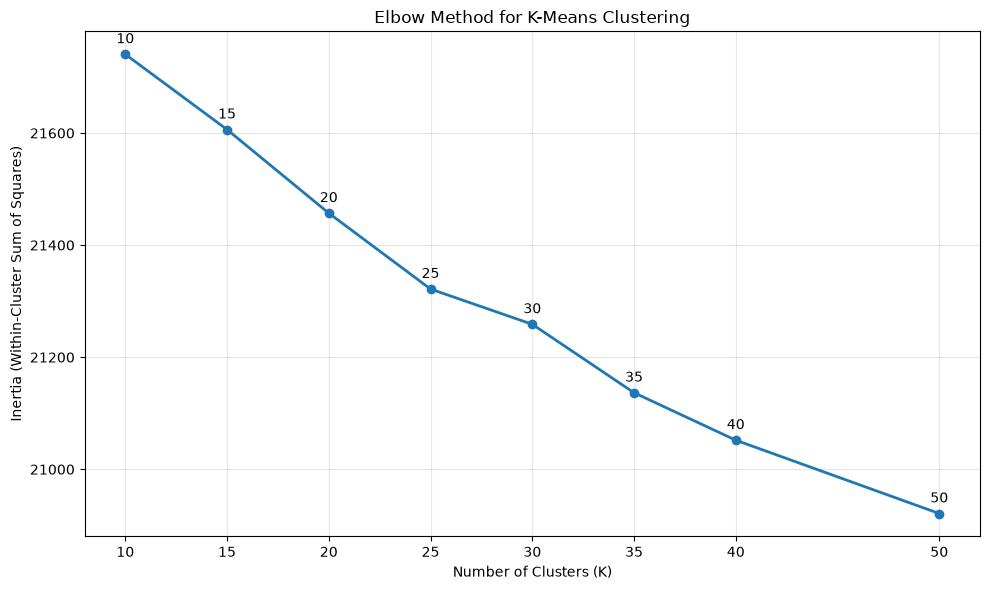

In [27]:
# Cell 25 — Elbow Method: Inertia vs Number of Clusters

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    k_evaluation_df["K"],
    k_evaluation_df["Inertia"],
    marker="o",
    linewidth=2
)

for _, row in k_evaluation_df.iterrows():
    plt.annotate(
        str(int(row["K"])),
        (row["K"], row["Inertia"]),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

plt.title("Elbow Method for K-Means Clustering")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (Within-Cluster Sum of Squares)")
plt.xticks(k_evaluation_df["K"])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
# Cell 26 — Quantify inertia improvements

elbow_analysis = k_evaluation_df[["K", "Inertia"]].copy()

elbow_analysis["Inertia Reduction"] = (
    elbow_analysis["Inertia"].shift(1) - elbow_analysis["Inertia"]
)

elbow_analysis["Reduction (%)"] = (
    elbow_analysis["Inertia Reduction"]
    / elbow_analysis["Inertia"].shift(1)
    * 100
)

display(elbow_analysis.round(3))

,K,Inertia,Inertia Reduction,Reduction (%)
0,10,21740.51,NaN,NaN
1,15,21606.15,134.36,0.618
2,20,21457.01,149.14,0.690
3,25,21321.63,135.38,0.631
4,30,21258.68,62.95,0.295
5,35,21136.56,122.12,0.574
6,40,21051.88,84.68,0.401
7,50,20921.02,130.86,0.622


Note: you may need to restart the kernel to use updated packages.
Estimated elbow K: None
Estimated knee K: None


E:\Anaconda3\Lib\site-packages\IPython\utils\_process_win32.py:138: ResourceWarning: unclosed file <_io.BufferedWriter name=5>
  res = process_handler(cmd, _system_body)
E:\Anaconda3\Lib\site-packages\IPython\utils\_process_win32.py:138: ResourceWarning: unclosed file <_io.BufferedReader name=6>
  res = process_handler(cmd, _system_body)
E:\Anaconda3\Lib\site-packages\IPython\utils\_process_win32.py:138: ResourceWarning: unclosed file <_io.BufferedReader name=7>
  res = process_handler(cmd, _system_body)


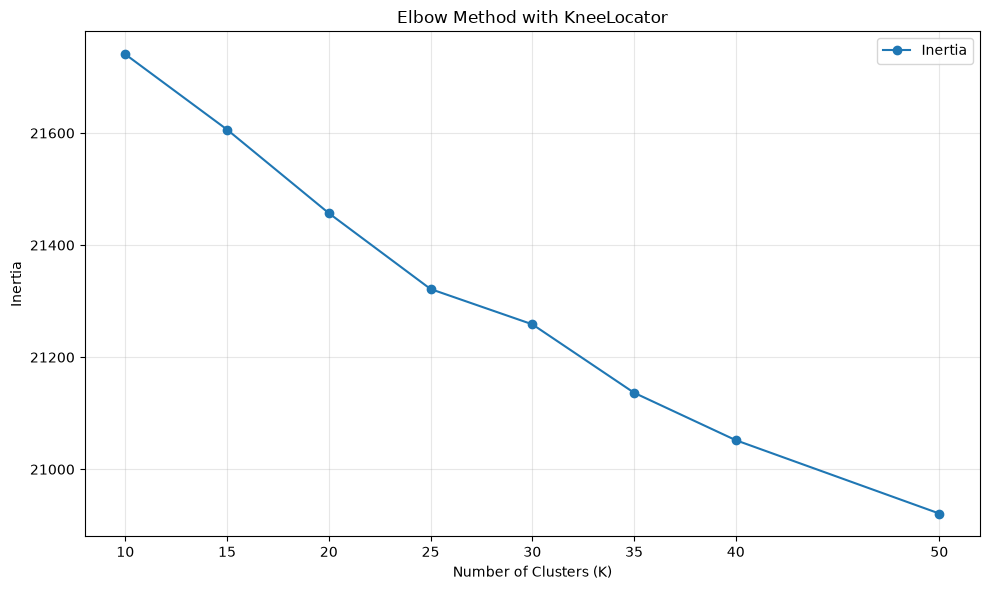

In [29]:
# Cell 27 — Estimate the elbow using KneeLocator

try:
    from kneed import KneeLocator
except ImportError:
    %pip install kneed
    from kneed import KneeLocator

knee_locator = KneeLocator(
    k_evaluation_df["K"].to_numpy(),
    k_evaluation_df["Inertia"].to_numpy(),
    curve="convex",
    direction="decreasing"
)

print("Estimated elbow K:", knee_locator.elbow)
print("Estimated knee K:", knee_locator.knee)

plt.figure(figsize=(10, 6))
plt.plot(
    k_evaluation_df["K"],
    k_evaluation_df["Inertia"],
    marker="o",
    label="Inertia"
)

if knee_locator.elbow is not None:
    plt.axvline(
        knee_locator.elbow,
        linestyle="--",
        label=f"Estimated elbow K = {knee_locator.elbow}"
    )

plt.title("Elbow Method with KneeLocator")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(k_evaluation_df["K"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [30]:
# Cell 28 — Summarize K selection evidence

print("ELBOW METHOD")
print("=" * 50)

print("Estimated elbow K:", knee_locator.elbow)

print("\nTOP CANDIDATES BY SILHOUETTE SCORE")
display(
    k_evaluation_df[
        ["K", "Silhouette (cosine)", "Inertia",
         "Largest Cluster (%)", "Training Time (s)"]
    ]
    .sort_values("Silhouette (cosine)", ascending=False)
    .reset_index(drop=True)
)

print("\nINTERPRETATION")
print("- The elbow estimates where inertia improvements begin to diminish.")
print("- Silhouette measures separation, but larger is not always more meaningful.")
print("- Cluster sizes and topic interpretability also matter.")
print("- The current tested range is limited; the elbow is not conclusive by itself.")

ELBOW METHOD
Estimated elbow K: None

TOP CANDIDATES BY SILHOUETTE SCORE


,K,Silhouette (cosine),Inertia,Largest Cluster (%),Training Time (s)
0,50,0.02827,20921.02,19.92,40.69
1,40,0.02734,21051.88,25.50,34.52
2,35,0.02611,21136.56,26.80,27.76
3,25,0.02446,21321.63,47.32,19.51
4,30,0.02421,21258.68,28.75,24.85
5,20,0.02168,21457.01,36.94,14.43
6,15,0.01864,21606.15,41.71,11.99
7,10,0.01521,21740.51,48.58,8.21



INTERPRETATION
- The elbow estimates where inertia improvements begin to diminish.
- Silhouette measures separation, but larger is not always more meaningful.
- Cluster sizes and topic interpretability also matter.
- The current tested range is limited; the elbow is not conclusive by itself.


In [31]:
# Cell 29 — Extend K-Means evaluation

additional_k_values = [55, 60, 65, 70, 80, 100]

additional_results = []

for k in additional_k_values:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=5,
        max_iter=300,
        random_state=42
    )

    start_time = time.time()
    labels = model.fit_predict(X_tfidf_stop)
    training_seconds = time.time() - start_time

    score = silhouette_score(
        X_silhouette_sample,
        labels[silhouette_sample_indices],
        metric="cosine"
    )

    cluster_sizes = pd.Series(labels).value_counts()

    additional_results.append({
        "K": k,
        "Inertia": round(model.inertia_, 2),
        "Silhouette (cosine)": round(score, 5),
        "Training Time (s)": round(training_seconds, 2),
        "Largest Cluster": int(cluster_sizes.max()),
        "Smallest Cluster": int(cluster_sizes.min()),
        "Largest Cluster (%)": round(
            cluster_sizes.max() / len(labels) * 100, 2
        )
    })

    print(
        f"K={k:3d} | Inertia={model.inertia_:.2f} | "
        f"Silhouette={score:.5f} | Time={training_seconds:.2f}s"
    )

additional_k_df = pd.DataFrame(additional_results)

k_evaluation_df = pd.concat(
    [k_evaluation_df, additional_k_df],
    ignore_index=True
).sort_values("K").reset_index(drop=True)

print("\nUPDATED K EVALUATION")
display(k_evaluation_df)

K= 55 | Inertia=20863.68 | Silhouette=0.02482 | Time=40.64s
K= 60 | Inertia=20819.63 | Silhouette=0.02951 | Time=45.16s
K= 65 | Inertia=20742.92 | Silhouette=0.03280 | Time=49.97s
K= 70 | Inertia=20696.74 | Silhouette=0.03039 | Time=57.70s
K= 80 | Inertia=20603.90 | Silhouette=0.02959 | Time=63.95s
K=100 | Inertia=20421.40 | Silhouette=0.03326 | Time=82.57s

UPDATED K EVALUATION


,K,Inertia,Silhouette (cosine),Training Time (s),Largest Cluster,Smallest Cluster,Largest Cluster (%),Empty Clusters
0,10,21740.51,0.01521,8.21,10861,384,48.58,0.0
1,15,21606.15,0.01864,11.99,9325,107,41.71,0.0
2,20,21457.01,0.02168,14.43,8259,152,36.94,0.0
3,25,21321.63,0.02446,19.51,10579,66,47.32,0.0
4,30,21258.68,0.02421,24.85,6428,58,28.75,0.0
5,35,21136.56,0.02611,27.76,5991,44,26.80,0.0
6,40,21051.88,0.02734,34.52,5700,44,25.50,0.0
7,50,20921.02,0.02827,40.69,4453,30,19.92,0.0
8,55,20863.68,0.02482,40.64,7241,29,32.39,NaN
9,60,20819.63,0.02951,45.16,4779,28,21.38,NaN


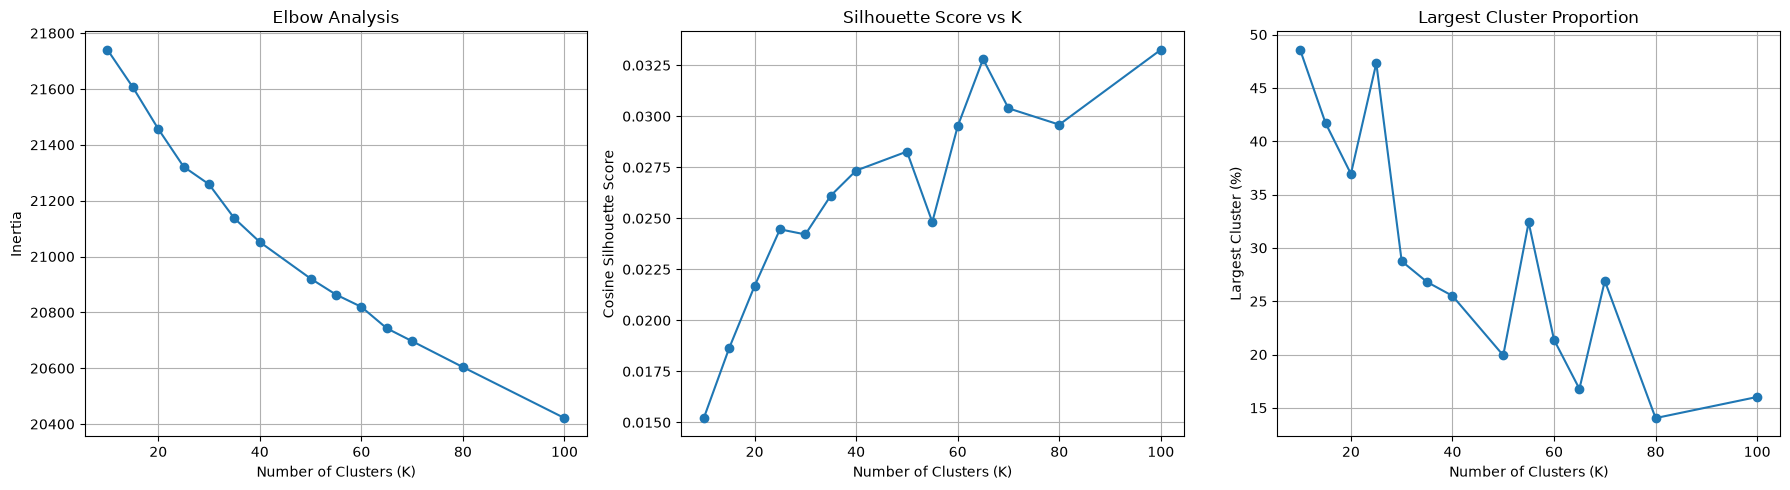

Highest silhouette score among tested K values:


,K,Inertia,Silhouette (cosine),Training Time (s),Largest Cluster,Smallest Cluster,Largest Cluster (%)
0,100,20421.40,0.03326,82.57,3582,14,16.02
1,65,20742.92,0.03280,49.97,3751,29,16.78
2,70,20696.74,0.03039,57.70,6013,29,26.90
3,80,20603.90,0.02959,63.95,3140,18,14.04
4,60,20819.63,0.02951,45.16,4779,28,21.38


In [32]:
# Cell 30 — Visualize the extended K-Means evaluation

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(k_evaluation_df["K"], k_evaluation_df["Inertia"], marker="o")
axes[0].set_title("Elbow Analysis")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].grid(True)

axes[1].plot(
    k_evaluation_df["K"],
    k_evaluation_df["Silhouette (cosine)"],
    marker="o"
)
axes[1].set_title("Silhouette Score vs K")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Cosine Silhouette Score")
axes[1].grid(True)

axes[2].plot(
    k_evaluation_df["K"],
    k_evaluation_df["Largest Cluster (%)"],
    marker="o"
)
axes[2].set_title("Largest Cluster Proportion")
axes[2].set_xlabel("Number of Clusters (K)")
axes[2].set_ylabel("Largest Cluster (%)")
axes[2].grid(True)

plt.tight_layout()
plt.show()

print("Highest silhouette score among tested K values:")
display(
    k_evaluation_df.nlargest(5, "Silhouette (cosine)")[
        [
            "K",
            "Inertia",
            "Silhouette (cosine)",
            "Training Time (s)",
            "Largest Cluster",
            "Smallest Cluster",
            "Largest Cluster (%)"
        ]
    ].reset_index(drop=True)
)

In [33]:
# Cell 31 — Compare candidate K values and calculate silhouette improvement

candidate_ks = [60, 65, 70, 80, 100]

candidate_comparison = (
    k_evaluation_df[k_evaluation_df["K"].isin(candidate_ks)]
    .sort_values("K")
    .copy()
)

candidate_comparison["Silhouette Change"] = (
    candidate_comparison["Silhouette (cosine)"].diff().round(5)
)

candidate_comparison["Inertia Reduction"] = (
    candidate_comparison["Inertia"].shift(1)
    - candidate_comparison["Inertia"]
).round(2)

display(candidate_comparison[
    [
        "K",
        "Inertia",
        "Inertia Reduction",
        "Silhouette (cosine)",
        "Silhouette Change",
        "Training Time (s)",
        "Largest Cluster (%)",
        "Smallest Cluster"
    ]
].reset_index(drop=True))

best_row = k_evaluation_df.loc[
    k_evaluation_df["Silhouette (cosine)"].idxmax()
]

print(f"\nBest tested K by silhouette: {int(best_row['K'])}")
print(f"Silhouette score: {best_row['Silhouette (cosine)']:.5f}")
print(f"Training time: {best_row['Training Time (s)']:.2f} seconds")
print(
    f"Largest cluster: {int(best_row['Largest Cluster'])} articles "
    f"({best_row['Largest Cluster (%)']:.2f}%)"
)

print(
    "\nNote: silhouette scores are approximate because they use a fixed "
    "sample. We should inspect cluster quality before choosing the final K."
)

,K,Inertia,Inertia Reduction,Silhouette (cosine),Silhouette Change,Training Time (s),Largest Cluster (%),Smallest Cluster
0,60,20819.63,NaN,0.02951,NaN,45.16,21.38,28
1,65,20742.92,76.71,0.03280,0.00329,49.97,16.78,29
2,70,20696.74,46.18,0.03039,-0.00241,57.70,26.90,29
3,80,20603.90,92.84,0.02959,-0.00080,63.95,14.04,18
4,100,20421.40,182.50,0.03326,0.00367,82.57,16.02,14



Best tested K by silhouette: 100
Silhouette score: 0.03326
Training time: 82.57 seconds
Largest cluster: 3582 articles (16.02%)

Note: silhouette scores are approximate because they use a fixed sample. We should inspect cluster quality before choosing the final K.


In [34]:
# Cell 32 — Inspect representative articles from candidate K-Means models

from sklearn.cluster import KMeans

candidate_ks = [65, 100]
candidate_models = {}

for k in candidate_ks:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=5,
        max_iter=300,
        random_state=42
    )
    labels = model.fit_predict(X_tfidf_stop)
    candidate_models[k] = model

    print(f"\n{'=' * 70}")
    print(f"K = {k}")
    print(f"Inertia: {model.inertia_:.2f}")
    print(f"Actual clusters: {len(np.unique(labels))}")

    cluster_sizes = pd.Series(labels).value_counts()
    print(f"Largest cluster: {cluster_sizes.max()} articles")
    print(f"Smallest cluster: {cluster_sizes.min()} articles")

    # Show the 10 largest clusters and their representative article titles.
    print("\nRepresentative articles from the 10 largest clusters:")

    for cluster_id, size in cluster_sizes.head(10).items():
        cluster_articles = model_df.loc[
            labels == cluster_id, ["title", "category", "clean_text"]
        ]

        print(f"\nCluster {cluster_id} | {size} articles")

        for _, article in cluster_articles.head(3).iterrows():
            title = str(article["title"]).strip()
            category = str(article["category"]).strip()
            print(f"  - [{category}] {title[:180]}")


K = 65
Inertia: 20742.92
Actual clusters: 65
Largest cluster: 3751 articles
Smallest cluster: 29 articles

Representative articles from the 10 largest clusters:

Cluster 0 | 3751 articles
  - [Stock] A Twist For Adam Neumann, Sam Altman, And The Fate Of Female Founders
  - [Stock] CyberPowerPC - Gamer Supreme Gaming Desktop - AMD Ryzen 9 7900X - 32GB Memory - NVIDIA GeForce RTX 4080 16GB - 2TB SSD - Black $2139.99
  - [Stock] Language That Could Be Added to the Buy-and-Hold Retirement Studies to Put Readers on Notice of Their Risks

Cluster 8 | 2112 articles
  - [Stock] Mets offseason primer: 5 burning questions, including how much will they spend?
  - [Stock] A new luxury menswear store opens in Edina's Galleria
  - [Stock] More Ginger, Less Seahorse

Cluster 24 | 1885 articles
  - [Stock] How to make money in the stock market
  - [Stock] 中国连续6个月减持美债 外汇储备不够用了？(图)
  - [Stock] IdeaForge enters US UAV market

Cluster 31 | 1151 articles
  - [Stock] Tenuta Villa Bellini - a meeting of his

In [35]:
# Cell 33 — Evaluate category consistency and topic coherence for K=65 and K=100

from collections import Counter

for k in [65, 100]:
    labels = candidate_models[k].labels_
    evaluation_df = model_df[["title", "category", "clean_text"]].copy()
    evaluation_df["cluster"] = labels

    print(f"\n{'=' * 75}")
    print(f"K = {k}: CATEGORY DISTRIBUTION WITHIN LARGEST CLUSTERS")
    print("=" * 75)

    largest_clusters = (
        evaluation_df["cluster"]
        .value_counts()
        .head(10)
        .index
    )

    for cluster_id in largest_clusters:
        cluster_data = evaluation_df[
            evaluation_df["cluster"] == cluster_id
        ]

        category_counts = cluster_data["category"].value_counts().head(5)

        print(
            f"\nCluster {cluster_id} | "
            f"{len(cluster_data)} articles | "
            f"{cluster_data['category'].nunique()} distinct categories"
        )
        print("Top categories:")
        print(category_counts.to_dict())

        print("Sample titles:")
        for title in cluster_data["title"].dropna().head(5):
            print(f"  - {str(title)[:150]}")


K = 65: CATEGORY DISTRIBUTION WITHIN LARGEST CLUSTERS

Cluster 0 | 3751 articles | 113 distinct categories
Top categories:
{'Home': 180, 'Politics': 175, 'Food': 138, 'Amazon': 128, 'Design': 112}
Sample titles:
  - A Twist For Adam Neumann, Sam Altman, And The Fate Of Female Founders
  - CyberPowerPC - Gamer Supreme Gaming Desktop - AMD Ryzen 9 7900X - 32GB Memory - NVIDIA GeForce RTX 4080 16GB - 2TB SSD - Black $2139.99
  - Language That Could Be Added to the Buy-and-Hold Retirement Studies to Put Readers on Notice of Their Risks
  - Fuel for thought: Can a driverless car get arrested?
  - Middle class shoplifters 'partly to blame for rise in retail crime'

Cluster 8 | 2112 articles | 99 distinct categories
Top categories:
{'Home': 151, 'Love': 141, 'History': 125, 'Games': 90, 'Australia': 69}
Sample titles:
  - Mets offseason primer: 5 burning questions, including how much will they spend?
  - A new luxury menswear store opens in Edina's Galleria
  - More Ginger, Less Seahorse
  -

In [36]:
# Train the final model using TF-IDF features with English stopwords removed

final_kmeans_model = KMeans(
    n_clusters=65,
    init="k-means++",
    n_init=10,
    max_iter=300,
    random_state=42,
    verbose=0
)

start_time = time.time()

final_kmeans_labels = final_kmeans_model.fit_predict(X_tfidf_stop)

final_training_time = time.time() - start_time

model_df["final_cluster"] = final_kmeans_labels

final_cluster_sizes = (
    model_df["final_cluster"]
    .value_counts()
    .sort_index()
)

print("FINAL K-MEANS MODEL — K = 65")
print("-" * 45)
print(f"Articles trained: {len(model_df):,}")
print(f"TF-IDF features: {X_tfidf_stop.shape[1]:,}")
print(f"Number of clusters: {final_kmeans_model.n_clusters}")
print(f"Training time: {final_training_time:.2f} seconds")
print(f"Inertia: {final_kmeans_model.inertia_:.4f}")
print(f"Iterations: {final_kmeans_model.n_iter_}")
print(f"Largest cluster: {final_cluster_sizes.max():,} articles")
print(f"Smallest cluster: {final_cluster_sizes.min():,} articles")
print(f"Empty clusters: {65 - len(final_cluster_sizes)}")
print(f"All articles assigned: {final_kmeans_labels.size == len(model_df)}")

FINAL K-MEANS MODEL — K = 65
---------------------------------------------
Articles trained: 22,357
TF-IDF features: 30,000
Number of clusters: 65
Training time: 331.68 seconds
Inertia: 20742.9238
Iterations: 40
Largest cluster: 3,751 articles
Smallest cluster: 29 articles
Empty clusters: 0
All articles assigned: True


In [37]:
# Identify the largest and smallest clusters in the final model

largest_cluster_id = int(final_cluster_sizes.idxmax())
smallest_cluster_id = int(final_cluster_sizes.idxmin())

clusters_to_inspect = [
    (largest_cluster_id, "LARGEST"),
    (smallest_cluster_id, "SMALLEST")
]

for cluster_id, cluster_type in clusters_to_inspect:
    cluster_articles = model_df.loc[
        model_df["final_cluster"] == cluster_id
    ]

    print("\n" + "=" * 100)
    print(f"{cluster_type} CLUSTER — ID: {cluster_id}")
    print(f"Total articles: {len(cluster_articles):,}")
    print("=" * 100)

    for i, (_, article) in enumerate(
        cluster_articles.head(5).iterrows(), start=1
    ):
        print(f"\nArticle {i}")
        print(f"Title: {article['title']}")
        print(f"Category: {article['category']}")
        print(f"Content: {article['clean_text'][:700]}")
        print("-" * 80)


LARGEST CLUSTER — ID: 0
Total articles: 3,751

Article 1
Title: A Twist For Adam Neumann, Sam Altman, And The Fate Of Female Founders
Category: Stock
Content: A Twist For Adam Neumann, Sam Altman, And The Fate Of Female Founders Adam Neumann the ousted WeWork CEO was again propelled into the public spotlight when the office "community" empire he built filed for bankruptcy. LOS ANGELES, CA - JANUARY 09: Adam Neumann speaks onstage during WeWork Presents Second Annual ... Creator Global Finals at Microsoft Theater on January 9, 2019 in Los Angeles, California. (Photo…
--------------------------------------------------------------------------------

Article 2
Title: CyberPowerPC - Gamer Supreme Gaming Desktop - AMD Ryzen 9 7900X - 32GB Memory - NVIDIA GeForce RTX 4080 16GB - 2TB SSD - Black $2139.99
Category: Stock
Content: CyberPowerPC - Gamer Supreme Gaming Desktop - AMD Ryzen 9 7900X - 32GB Memory - NVIDIA GeForce RTX 4080 16GB - 2TB SSD - Black $2139.99 *Specs:* * AMD Ryzen 9 7900X *

In [38]:
# Cell 37 — Compare articles from the five largest and smallest clusters

cluster_sizes = model_df["final_cluster"].value_counts()

largest_clusters = cluster_sizes.nlargest(5)
smallest_clusters = cluster_sizes.nsmallest(5)

for group_name, selected_clusters in [
    ("FIVE LARGEST CLUSTERS", largest_clusters),
    ("FIVE SMALLEST CLUSTERS", smallest_clusters)
]:
    print("\n" + "=" * 100)
    print(group_name)
    print("=" * 100)

    for cluster_id, size in selected_clusters.items():
        articles = model_df.loc[
            model_df["final_cluster"] == cluster_id
        ]

        print(f"\nCluster {cluster_id} | Articles: {size:,}")

        for i, (_, article) in enumerate(
            articles.head(5).iterrows(), start=1
        ):
            title = article["title"]
            category = article["category"]

            print(f"{i}. [{category}] {title}")


FIVE LARGEST CLUSTERS

Cluster 0 | Articles: 3,751
1. [Stock] A Twist For Adam Neumann, Sam Altman, And The Fate Of Female Founders
2. [Stock] CyberPowerPC - Gamer Supreme Gaming Desktop - AMD Ryzen 9 7900X - 32GB Memory - NVIDIA GeForce RTX 4080 16GB - 2TB SSD - Black $2139.99
3. [Stock] Language That Could Be Added to the Buy-and-Hold Retirement Studies to Put Readers on Notice of Their Risks
4. [Stock] Fuel for thought: Can a driverless car get arrested?
5. [Stock] Middle class shoplifters 'partly to blame for rise in retail crime'

Cluster 8 | Articles: 2,112
1. [Stock] Mets offseason primer: 5 burning questions, including how much will they spend?
2. [Stock] A new luxury menswear store opens in Edina's Galleria
3. [Stock] More Ginger, Less Seahorse
4. [Home] F1 Finds Its Spiritual Home In The Chaos Of Las Vegas
5. [Home] George R.R. Martin Has No (New) Pages

Cluster 24 | Articles: 1,885
1. [Stock] How to make money in the stock market
2. [Stock] 中国连续6个月减持美债 外汇储备不够用了？(图)
3. [Stoc

In [39]:
# Cell 38 — Identify the terms defining the largest and smallest clusters

feature_names = tfidf_stop_vectorizer.get_feature_names_out()

cluster_sizes = model_df["final_cluster"].value_counts()

clusters_to_inspect = pd.concat([
    cluster_sizes.nlargest(5),
    cluster_sizes.nsmallest(5)
]).loc[lambda x: ~x.index.duplicated()]

for cluster_id, size in clusters_to_inspect.items():
    centroid = final_kmeans_model.cluster_centers_[cluster_id]

    top_indices = np.argsort(centroid)[-15:][::-1]
    top_terms = feature_names[top_indices]

    print("\n" + "=" * 80)
    print(f"Cluster ID: {cluster_id} | Articles: {size:,}")
    print("Top defining terms:")
    print(", ".join(top_terms))


Cluster ID: 0 | Articles: 3,751
Top defining terms:
amazon, court, na, president, state, said, pro, post, 2023, people, government, 10, az, 000, design

Cluster ID: 8 | Articles: 2,112
Top defining terms:
new, year, years, old, season, series, time, world, year old, star, film, team, game, end, new york

Cluster ID: 24 | Articles: 1,885
Top defining terms:
china, india, year, tuesday, market, bank, new, said, com, marketscreener, marketscreener com, company, growth, stock, global

Cluster ID: 31 | Articles: 1,151
Top defining terms:
just, love, like, make, best, people, way, post, want, know, world, things, time, don, life

Cluster ID: 29 | Articles: 814
Top defining terms:
le, la, les, et, des, en, une, du, pour, dans, est, sur, au, qui, ce

Cluster ID: 14 | Articles: 29
Top defining terms:
代表者, 神奈川県川崎市, 神奈川県川崎市 代表者, 証券コート, 証券コート 東証スタンタート, 市場調査レホート, 所在地 神奈川県川崎市, 4171 市場調査レホート, 株式会社クローハルインフォメーション 所在地, 株式会社クローハルインフォメーション, 4171, 東証スタンタート 4171, 東証スタンタート, の販売を11月21日より開始いたしました, 所在地

Cluste

In [40]:
# Cell 38 — Extract articles and TF-IDF features for Cluster 0

parent_cluster_id = 0

cluster_0_mask = (
    model_df["final_cluster"] == parent_cluster_id
)

cluster_0_df = model_df.loc[cluster_0_mask].copy()

# Reuse the existing TF-IDF representation
X_cluster_0 = X_tfidf_stop[cluster_0_mask.to_numpy()]

print("PARENT CLUSTER EXTRACTION")
print("=" * 50)
print(f"Parent cluster: {parent_cluster_id}")
print(f"Articles extracted: {len(cluster_0_df):,}")
print(f"TF-IDF features: {X_cluster_0.shape[1]:,}")
print(f"Non-zero TF-IDF values: {X_cluster_0.nnz:,}")
print(f"Feature matrix shape: {X_cluster_0.shape}")
print(f"Original cluster remains unchanged: "
      f"(model_df['final_cluster'] == 0).sum() == {len(cluster_0_df)}")

PARENT CLUSTER EXTRACTION
Parent cluster: 0
Articles extracted: 3,751
TF-IDF features: 30,000
Non-zero TF-IDF values: 93,066
Feature matrix shape: (3751, 30000)
Original cluster remains unchanged: (model_df['final_cluster'] == 0).sum() == 3751


In [41]:
# Cell 40 — Evaluate candidate K values within parent Cluster 0

from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
import time

candidate_subcluster_ks = [3, 5, 8, 10, 12]
subcluster_results = []

# Fixed sample for comparable silhouette scores
rng = np.random.RandomState(42)
sample_size = min(1500, X_cluster_0.shape[0])
sample_indices = np.sort(
    rng.choice(X_cluster_0.shape[0], size=sample_size, replace=False)
)
X_cluster_0_sample = X_cluster_0[sample_indices]

for k in candidate_subcluster_ks:
    sub_model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=5,
        max_iter=300,
        random_state=42
    )

    start_time = time.time()
    sub_labels = sub_model.fit_predict(X_cluster_0)
    elapsed = time.time() - start_time

    sample_labels = sub_labels[sample_indices]
    silhouette = silhouette_score(
        X_cluster_0_sample,
        sample_labels,
        metric="cosine"
    )

    sizes = pd.Series(sub_labels).value_counts()

    subcluster_results.append({
        "K": k,
        "Inertia": sub_model.inertia_,
        "Silhouette": silhouette,
        "Training_Time_sec": round(elapsed, 2),
        "Largest_Cluster_Size": int(sizes.max()),
        "Smallest_Cluster_Size": int(sizes.min())
    })

subcluster_evaluation_df = pd.DataFrame(subcluster_results)

display(
    subcluster_evaluation_df.round(5)
)

,K,Inertia,Silhouette,Training_Time_sec,Largest_Cluster_Size,Smallest_Cluster_Size
0,3,3714.37598,0.00287,1.28,3374,185
1,5,3697.17627,0.00535,2.36,3071,66
2,8,3678.98340,0.00793,5.13,2469,28
3,10,3664.98633,0.01092,5.70,2255,34
4,12,3644.08643,0.01309,6.46,2495,15


In [42]:
# Cell 41 — Inspect subclusters within original Cluster 0

subcluster_model = KMeans(
    n_clusters=12,
    init="k-means++",
    n_init=10,
    max_iter=300,
    random_state=42
)

subcluster_labels = subcluster_model.fit_predict(X_cluster_0)

cluster_0_df["subcluster"] = subcluster_labels

subcluster_sizes = (
    cluster_0_df["subcluster"]
    .value_counts()
    .sort_values(ascending=False)
)

print("SECOND-LEVEL CLUSTERING — PARENT CLUSTER 0")
print("=" * 80)
print(f"Parent articles: {len(cluster_0_df):,}")
print(f"Subclusters: {subcluster_model.n_clusters}")

for label in list(subcluster_sizes.head(3).index) + list(subcluster_sizes.tail(3).index):
    articles = cluster_0_df.loc[
        cluster_0_df["subcluster"] == label
    ]

    print(f"\n{'-' * 80}")
    print(f"Subcluster {label} | Articles: {len(articles):,}")

    for i, (_, article) in enumerate(
        articles.head(5).iterrows(), start=1
    ):
        print(f"{i}. [{article['category']}] {article['title']}")

SECOND-LEVEL CLUSTERING — PARENT CLUSTER 0
Parent articles: 3,751
Subclusters: 12

--------------------------------------------------------------------------------
Subcluster 9 | Articles: 2,495
1. [Stock] A Twist For Adam Neumann, Sam Altman, And The Fate Of Female Founders
2. [Stock] CyberPowerPC - Gamer Supreme Gaming Desktop - AMD Ryzen 9 7900X - 32GB Memory - NVIDIA GeForce RTX 4080 16GB - 2TB SSD - Black $2139.99
3. [Stock] Language That Could Be Added to the Buy-and-Hold Retirement Studies to Put Readers on Notice of Their Risks
4. [Stock] Fuel for thought: Can a driverless car get arrested?
5. [Stock] Middle class shoplifters 'partly to blame for rise in retail crime'

--------------------------------------------------------------------------------
Subcluster 2 | Articles: 307
1. [Home] KCR standing on slippery pitch in his home state: Devendra Fadnavis
2. [Home] More than 400,000 Afghans have returned from Pakistan in migrant crackdown
3. [Home] Azerbaijan arrests two journali

In [43]:
# Cell 42 — Inspect the largest second-level subcluster

parent_subcluster_id = 9

subcluster_9_mask = (
    cluster_0_df["subcluster"] == parent_subcluster_id
)

subcluster_9_df = cluster_0_df.loc[subcluster_9_mask].copy()

X_subcluster_9 = X_cluster_0[subcluster_9_mask.to_numpy()]

feature_names = tfidf_stop_vectorizer.get_feature_names_out()

centroid = subcluster_model.cluster_centers_[parent_subcluster_id]

top_indices = np.argsort(centroid)[-30:][::-1]
top_terms = feature_names[top_indices]

print("SUBCLUSTER 9 ANALYSIS")
print("=" * 70)
print(f"Articles: {len(subcluster_9_df):,}")
print(f"Feature matrix shape: {X_subcluster_9.shape}")
print("\nTop 30 defining terms:")
print(", ".join(top_terms))

print("\nSample article titles:")
for i, title in enumerate(subcluster_9_df["title"].head(15), start=1):
    print(f"{i}. {title}")

SUBCLUSTER 9 ANALYSIS
Articles: 2,495
Feature matrix shape: (2495, 30000)

Top 30 defining terms:
10, home, state, post, japan, said, 2023, 000, police, people, data, government, design, time, 12, world, national, air, 100, high, city, million, online, power, service, 11, 20, week, use, security

Sample article titles:
1. A Twist For Adam Neumann, Sam Altman, And The Fate Of Female Founders
2. CyberPowerPC - Gamer Supreme Gaming Desktop - AMD Ryzen 9 7900X - 32GB Memory - NVIDIA GeForce RTX 4080 16GB - 2TB SSD - Black $2139.99
3. Language That Could Be Added to the Buy-and-Hold Retirement Studies to Put Readers on Notice of Their Risks
4. Fuel for thought: Can a driverless car get arrested?
5. Middle class shoplifters 'partly to blame for rise in retail crime'
6. FreeBSD 14 Released
7. Keebin’ with Kristina: the One With the Duplex Typewriter
8. Can Pedro Paiva Save Portuguese Cider?
9. This slim laptop sleeve doubles as a portable desk mat and wireless charger
10. Higherdose Infrared 

In [44]:
# Cell 43 — Evaluate recursive clustering within Subcluster 9

candidate_ks_level3 = [5, 8, 10, 15]
level3_results = []

rng = np.random.RandomState(42)
sample_size = min(1200, X_subcluster_9.shape[0])

sample_indices_level3 = np.sort(
    rng.choice(
        X_subcluster_9.shape[0],
        size=sample_size,
        replace=False
    )
)

X_subcluster_9_sample = X_subcluster_9[sample_indices_level3]

for k in candidate_ks_level3:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=5,
        max_iter=300,
        random_state=42
    )

    start_time = time.time()
    labels = model.fit_predict(X_subcluster_9)
    elapsed = time.time() - start_time

    sample_labels = labels[sample_indices_level3]

    score = silhouette_score(
        X_subcluster_9_sample,
        sample_labels,
        metric="cosine"
    )

    sizes = pd.Series(labels).value_counts()

    level3_results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette": score,
        "Training_Time_sec": round(elapsed, 2),
        "Largest_Cluster_Size": int(sizes.max()),
        "Smallest_Cluster_Size": int(sizes.min())
    })

level3_evaluation_df = pd.DataFrame(level3_results)

display(level3_evaluation_df.round(5))

,K,Inertia,Silhouette,Training_Time_sec,Largest_Cluster_Size,Smallest_Cluster_Size
0,5,2468.14551,0.00278,2.38,1679,42
1,8,2459.91016,0.00450,6.12,1200,42
2,10,2456.26880,0.00448,3.45,945,50
3,15,2442.28857,0.00640,5.52,510,9


In [45]:
# Cell 44 — Inspect candidate K=15 clusters within Subcluster 9

level3_model = KMeans(
    n_clusters=15,
    init="k-means++",
    n_init=10,
    max_iter=300,
    random_state=42
)

level3_labels = level3_model.fit_predict(X_subcluster_9)

subcluster_9_df["level3_cluster"] = level3_labels

level3_sizes = (
    subcluster_9_df["level3_cluster"]
    .value_counts()
    .sort_values(ascending=False)
)

selected_level3_clusters = list(level3_sizes.head(3).index)

for cluster_id in level3_sizes.tail(3).index:
    if cluster_id not in selected_level3_clusters:
        selected_level3_clusters.append(cluster_id)

for cluster_id in selected_level3_clusters:
    articles = subcluster_9_df.loc[
        subcluster_9_df["level3_cluster"] == cluster_id
    ]

    print("\n" + "=" * 85)
    print(f"Subcluster {cluster_id} | Articles: {len(articles):,}")
    print("=" * 85)

    for i, (_, article) in enumerate(
        articles.head(5).iterrows(), start=1
    ):
        print(f"{i}. [{article['category']}] {article['title']}")


Subcluster 0 | Articles: 510
1. [Home] Kim Zolciak and Kroy Biermann's Child Calls Cops After Explosive Fight
2. [Home] 5 UPS workers shared the toughest parts of their jobs: 'Sleeping on a truck four nights a week is rough'
3. [Home] She was elated about her pregnancy. Then came a $2,400 bill for blood tests
4. [Home] Windows 10向けのCopilot in Windowsがリリースプレビューチャネルで提供開始
5. [Home] Massive 6-unit shipping container home.

Subcluster 10 | Articles: 245
1. [Home] Keebin’ with Kristina: the One With the Duplex Typewriter
2. [Home] TIME’s Top 100 Photos of 2023
3. [Home] Olympic champion Price announces next pro fight
4. [Home] MJ Lenderman: And the Wind (Live and Loose!)
5. [Home] Former Chicago Mayor Rahm Emanuel's Michigan home spray-painted with the word 'Nazis' (Chicago Sun Times)

Subcluster 6 | Articles: 205
1. [Stock] Middle class shoplifters 'partly to blame for rise in retail crime'
2. [Home] Embracing the Mediterranean Lifestyle at Zel Mallorca
3. [Home] Easylkb: Easy Linux Kernel

In [46]:
# Cell 45 — Inspect the remaining level-3 clusters for topic coherence

for cluster_id in level3_sizes.index[3:-3]:
    articles = subcluster_9_df.loc[
        subcluster_9_df["level3_cluster"] == cluster_id
    ]
    print("\n" + "=" * 85)
    print(f"Subcluster {cluster_id} | Articles: {len(articles):,}")
    print("=" * 85)

    for i, (_, article) in enumerate(articles.head(5).iterrows(), start=1):
        print(f"{i}. [{article['category']}] {article['title']}")


Subcluster 2 | Articles: 200
1. [Home] More than 100 guns stolen in Michigan after store manager forced to reveal alarm code
2. [Home] A novel prison program for pregnant women and their babies
3. [Home] See a plane that landed in the water after it overshot the runway in Hawaii
4. [Home] I'm a housekeeper at a hotel where a 1-night stay costs more than I make in 2 weeks
5. [Home] Navy Plane Overshoots Runway And Ends Up In Ocean

Subcluster 12 | Articles: 190
1. [Stock] Language That Could Be Added to the Buy-and-Hold Retirement Studies to Put Readers on Notice of Their Risks
2. [Home] This 3D printed social housing apartment building aims to become Europe's first of its kind
3. [Home] Well-Paid Maids Now Offering Recurring Customer Discounts!
4. [Home] US Cybersecurity Lab Suffers Major Data Breach
5. [Love] A Sneak Peek at Galfer's Prototype Hydraulic Brakes

Subcluster 3 | Articles: 183
1. [Stock] Fuel for thought: Can a driverless car get arrested?
2. [Home] Higherdose Infrared S

In [47]:
# Cell 46 — Review topic coherence across the recursive clustering results

feature_names = tfidf_stop_vectorizer.get_feature_names_out()

for cluster_id in level3_sizes.index:
    articles = subcluster_9_df.loc[
        subcluster_9_df["level3_cluster"] == cluster_id
    ]
    centroid = level3_model.cluster_centers_[cluster_id]
    top_indices = np.argsort(centroid)[-15:][::-1]
    top_terms = feature_names[top_indices]

    print(
        f"Cluster {cluster_id:>2} | "
        f"Articles: {len(articles):>4} | "
        f"Top terms: {', '.join(top_terms)}"
    )

Cluster  0 | Articles:  510 | Top terms: ja, 画像, japan, suomen, etta, death, itarajan, office, می, tiistaina, 100, 共同通信jbn, از, galaxy, newswire 共同通信jbn
Cluster 10 | Articles:  245 | Top terms: online, gold, time, nintendo, 12, article, points, switch, read, com, switch online, practices, history, available, point
Cluster  6 | Articles:  205 | Top terms: amp, use, 2023, coast, plan, heavy, technology, protect, credit, problem, environment, attacks, image, amp amp, tool
Cluster  2 | Articles:  200 | Top terms: said, authorities, people, monday, homes, town, navy, officials, aircraft, home, hawaii, runway, dead, remote, plane
Cluster 12 | Articles:  190 | Top terms: data, million, vulnerability, added, provider, government, breach, private, company, security, victims, services, growing, customer, service
Cluster  3 | Articles:  183 | Top terms: police, home, court, violence, arrested, tuesday, charge, face, state, wife, allegedly, man, women, officers, government
Cluster  1 | Articles:  

In [48]:
# Cell 47 — Analyze text quality before improving preprocessing

text_quality = pd.DataFrame({
    "article_id": model_df["article_id"],
    "title": model_df["title"],
    "clean_text": model_df["clean_text"],
    "text_length": model_df["clean_text"].str.len(),
    "word_count": model_df["clean_text"].str.split().str.len(),
    "unique_word_ratio": model_df["clean_text"].apply(
        lambda text: len(set(text.lower().split())) / max(len(text.split()), 1)
    )
})

print("TEXT QUALITY SUMMARY")
print(text_quality[["text_length", "word_count", "unique_word_ratio"]].describe().round(3))

print("\nSHORTEST ARTICLES")
display(
    text_quality.nsmallest(10, "word_count")[
        ["article_id", "title", "word_count", "clean_text"]
    ]
)

print("\nLONGEST ARTICLES")
display(
    text_quality.nlargest(10, "word_count")[
        ["article_id", "title", "word_count", "clean_text"]
    ]
)

TEXT QUALITY SUMMARY
       text_length  word_count  unique_word_ratio
count    22357.000   22357.000          22357.000
mean       465.476      74.081              0.649
std         83.269      16.774              0.144
min         73.000       3.000              0.302
25%        405.000      64.000              0.524
50%        488.000      76.000              0.627
75%        530.000      86.000              0.772
max       1050.000     174.000              1.000

SHORTEST ARTICLES


,article_id,title,word_count,clean_text
3489,598751,韓国人「来年から変わるペプシコーラのロゴをご覧ください」,3,韓国人「来年から変わるペプシコーラのロゴをご覧ください」 韓国のネット掲示板イルベに「来年か...
12951,618863,Amazonブラックフライデーでゲーミングマウスがお得。ロジクールやRazer、MSIなどの...,4,Amazonブラックフライデーでゲーミングマウスがお得。ロジクールやRazer、MSIなどの...
13600,618816,本日みつけたお買い得品トイレや脱衣所など寒いスポットに。数千円で買えるセラミックファンヒーター,4,本日みつけたお買い得品トイレや脱衣所など寒いスポットに。数千円で買えるセラミックファンヒータ...
17485,623793,内田瑞穂、胸元が露わになった姿を披露しファン大興奮「かわいすぎだしセクシーすぎです」「抱きし...,6,内田瑞穂、胸元が露わになった姿を披露しファン大興奮「かわいすぎだしセクシーすぎです」「抱きし...
18779,625871,虹のコンキスタドールから山崎夏菜＆大塚望由が卒業,6,虹のコンキスタドールから山崎夏菜＆大塚望由が卒業 虹のコンキスタドールのメンバー、山崎夏菜と...
10413,610516,「X-CON」開催中止にファン怒り,7,「X-CON」開催中止にファン怒り 12月8〜10日の3日間にわたり千葉・幕張メッセで初開催...
21867,633125,中国当局、ゲーム配信大手「闘魚」のＣＥＯを拘束,7,中国当局、ゲーム配信大手「闘魚」のＣＥＯを拘束 中国のゲーム映像配信大手「闘魚（ドウユウ）」...
4207,599817,海外「今はもう日本の時代なんだな…」 米軍(FBI)が兵士の募集に日本のアニメを利用し始め大...,8,海外「今はもう日本の時代なんだな…」 米軍(FBI)が兵士の募集に日本のアニメを利用し始め大...
7691,605179,思想者书店｜形式主义折腾得基层已经无法干正事了,8,思想者书店｜形式主义折腾得基层已经无法干正事了 基层普遍陷入了“无事找事”的怪圈里。上级就怕...
7692,605181,冷杉｜一个卧底，和上百个被拐的孩子,8,冷杉｜一个卧底，和上百个被拐的孩子 今年是上官正义做民间打拐的第16年。他的真实身份和赛博身...



LONGEST ARTICLES


,article_id,title,word_count,clean_text
6357,603065,PER CHI RI-SUONA LA MOTOSEGA DEL NUOVO PRESIDE...,174,PER CHI RI-SUONA LA MOTOSEGA DEL NUOVO PRESIDE...
11733,613402,BOCCIATA O PROMOSSA? IL SOLITO COMPROMESSO EUR...,171,BOCCIATA O PROMOSSA? IL SOLITO COMPROMESSO EUR...
6606,603409,“A 22 ANNI NON C’È AREA DEL GIOCO DI JANNIK CH...,164,“A 22 ANNI NON C’È AREA DEL GIOCO DI JANNIK CH...
10191,610102,“HO FATTO IL ’68 CON LA PELLICCIA AL POSTO DEL...,161,“HO FATTO IL ’68 CON LA PELLICCIA AL POSTO DEL...
6620,603443,सोनार पल्स क्या है? पानी के नीचे मनुष्यों को घ...,155,सोनार पल्स क्या है? पानी के नीचे मनुष्यों को घ...
11605,613165,"LA ""BOBOTV""? È TUTTO UN MAGNA ""MAGNAGER"" - COM...",155,"LA ""BOBOTV""? È TUTTO UN MAGNA ""MAGNAGER"" - COM..."
21298,631792,COSA PREVEDE L'ACCORDO TRA ISRAELE E HAMAS PER...,154,COSA PREVEDE L'ACCORDO TRA ISRAELE E HAMAS PER...
17767,624166,“VOGLIONO FARMI APPARIRE VIOLENTO E MALEDUCATO...,150,“VOGLIONO FARMI APPARIRE VIOLENTO E MALEDUCATO...
6241,602933,IL “LOCO” È PRONTO A FAR DANNI - IL NEO-PRESID...,149,IL “LOCO” È PRONTO A FAR DANNI - IL NEO-PRESID...
13129,617584,MELONI E CRAUTI – LA PREMIER ITALIANA ATTERRA ...,149,MELONI E CRAUTI – LA PREMIER ITALIANA ATTERRA ...


In [49]:
# Cell 48 — Detect language, boilerplate, and noisy text patterns

import re
from collections import Counter

sample_text = model_df["clean_text"].fillna("")

patterns_to_check = {
    "URLs": r"https?://\S+|www\.\S+",
    "Email addresses": r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b",
    "HTML remnants": r"<[^>]+>",
    "Repeated punctuation": r"[!?.,]{3,}",
    "Bracketed metadata": r"\[[^\]]{0,80}\]",
    "Publisher-style markers": r"\b(?:published|originally published|editorial|newswire|press release)\b",
    "Tracking/placeholder tokens": r"\b(?:utm_source|undefined|null|nan)\b",
}

print("NOISE PATTERN COUNTS")
for name, pattern in patterns_to_check.items():
    matches_per_article = sample_text.str.contains(
        pattern, case=False, regex=True, na=False
    )
    print(f"{name:30s}: {int(matches_per_article.sum()):,} articles")

print("\nCOMMON NON-ALPHABETIC TOKENS")
token_counter = Counter()
for text in sample_text:
    token_counter.update(
        token.lower()
        for token in re.findall(r"\b[^\W\d_][\w'-]*\b", text, flags=re.UNICODE)
        if len(token) <= 3
    )

print(token_counter.most_common(40))

print("\nSAMPLE ARTICLES WITH URL OR PUBLISHER MARKERS")
noise_pattern = (
    r"https?://\S+|www\.\S+|"
    r"\b(?:published|originally published|editorial|newswire|press release)\b"
)
noise_examples = model_df.loc[
    sample_text.str.contains(noise_pattern, case=False, regex=True, na=False),
    ["article_id", "title", "clean_text"]
].head(12)

display(noise_examples)

NOISE PATTERN COUNTS
URLs                          : 0 articles
Email addresses               : 31 articles
HTML remnants                 : 0 articles
Repeated punctuation          : 1,971 articles
Bracketed metadata            : 936 articles
Publisher-style markers       : 870 articles
Tracking/placeholder tokens   : 10 articles

COMMON NON-ALPHABETIC TOKENS
[('the', 58649), ('a', 32815), ('of', 28021), ('to', 27442), ('in', 26261), ('and', 23168), ('de', 16430), ('on', 14002), ('for', 12622), ('is', 11028), ('la', 8102), ('s', 7695), ('as', 7168), ('has', 6887), ('by', 6398), ('at', 6380), ('en', 5719), ('its', 5308), ('new', 4891), ('it', 4849), ('an', 4808), ('are', 4400), ('el', 4204), ('que', 3820), ('was', 3492), ('you', 3197), ('be', 3166), ('i', 3157), ('un', 3154), ('le', 2804), ('y', 2652), ('but', 2518), ('his', 2515), ('up', 2274), ('die', 2247), ('com', 2146), ('e', 2109), ('we', 2063), ('del', 2021), ('one', 2014)]

SAMPLE ARTICLES WITH URL OR PUBLISHER MARKERS


,article_id,title,clean_text
91,594529,CSG Systems International (NASDAQ:CSGS) Stock ...,CSG Systems International (NASDAQ:CSGS) Stock ...
119,594559,Language That Could Be Added to the Buy-and-Ho...,Language That Could Be Added to the Buy-and-Ho...
120,594560,my rich friend is oblivious when he talks abou...,my rich friend is oblivious when he talks abou...
185,594815,‘The Heck Do Ya Mean?’: 15 Trivia Tidbits Abou...,‘The Heck Do Ya Mean?’: 15 Trivia Tidbits Abou...
222,594658,BowFlex (NYSE:NLS) Now Covered by Analysts at ...,BowFlex (NYSE:NLS) Now Covered by Analysts at ...
235,594671,Why ‘Climate Havens’ Could Be Closer to Home T...,Why ‘Climate Havens’ Could Be Closer to Home T...
346,594786,Pirate IPTV: Brit Arrested in Benidorm After S...,Pirate IPTV: Brit Arrested in Benidorm After S...
425,594875,Africa: South Africa Mulls Major Immigration O...,Africa: South Africa Mulls Major Immigration O...
430,594881,Azerbaijan arrests two journalists investigati...,Azerbaijan arrests two journalists investigati...
500,594953,"‘The Curse’ Is An Insufferable, Overlong Genre...","‘The Curse’ Is An Insufferable, Overlong Genre..."


In [50]:
# Cell 49 — Create improved text with conservative noise cleanup

import html
import unicodedata

def improve_article_text(text):
    text = "" if pd.isna(text) else str(text)
    text = html.unescape(text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text, flags=re.IGNORECASE)
    text = re.sub(r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\[\+\s*\d+\s*chars?\]", " ", text, flags=re.IGNORECASE)
    text = re.sub(r"\[\+\s*\]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

model_df["improved_text"] = model_df["clean_text"].map(improve_article_text)

print("Original articles:", len(model_df))
print("Empty improved texts:", int(model_df["improved_text"].str.strip().eq("").sum()))
print("Original vs improved text lengths:")
display(pd.DataFrame({
    "original_length": model_df["clean_text"].str.len(),
    "improved_length": model_df["improved_text"].str.len()
}).describe().round(2))

print("\nExamples where text changed:")
changed = model_df["clean_text"] != model_df["improved_text"]
display(
    model_df.loc[changed, ["article_id", "title", "clean_text", "improved_text"]]
    .head(8)
)

Original articles: 22357
Empty improved texts: 0
Original vs improved text lengths:


,original_length,improved_length
count,22357.00,22357.00
mean,465.48,465.27
std,83.27,83.31
min,73.00,73.00
25%,405.00,405.00
50%,488.00,488.00
75%,530.00,529.00
max,1050.00,1050.00



Examples where text changed:


,article_id,title,clean_text,improved_text
11,594436,"15 ""Bad"" Movies People Still Love","15 ""Bad"" Movies People Still Love Some movies ...","15 ""Bad"" Movies People Still Love Some movies ..."
30,594455,D.A. Davidson & CO. Boosts Stock Position in A...,D.A. Davidson & CO. Boosts Stock Position in A...,D.A. Davidson & CO. Boosts Stock Position in A...
36,594461,D.A. Davidson & CO. Decreases Stock Holdings i...,D.A. Davidson & CO. Decreases Stock Holdings i...,D.A. Davidson & CO. Decreases Stock Holdings i...
40,594465,PG&E (NYSE:PCG) Stock Rating Upgraded by Stock...,PG&E (NYSE:PCG) Stock Rating Upgraded by Stock...,PG&E (NYSE:PCG) Stock Rating Upgraded by Stock...
70,594545,Christmas has come early for the stock market,Christmas has come early for the stock market ...,Christmas has come early for the stock market ...
103,594541,Deere & Company (NYSE:DE) Stock Holdings Lifte...,Deere & Company (NYSE:DE) Stock Holdings Lifte...,Deere & Company (NYSE:DE) Stock Holdings Lifte...
123,594564,A new luxury menswear store opens in Edina's G...,A new luxury menswear store opens in Edina's G...,A new luxury menswear store opens in Edina's G...
146,594586,Abercrombie & Fitch raises outlook after quart...,Abercrombie & Fitch raises outlook after quart...,Abercrombie & Fitch raises outlook after quart...


In [51]:
# Cell 50 — Build improved multilingual TF-IDF representation

from sklearn.feature_extraction.text import TfidfVectorizer

improved_vectorizer = TfidfVectorizer(
    max_features=40000,
    min_df=3,
    max_df=0.85,
    ngram_range=(1, 2),
    sublinear_tf=True,
    strip_accents="unicode",
    stop_words="english",
    dtype=np.float32
)

X_tfidf_improved = improved_vectorizer.fit_transform(model_df["improved_text"])

print("Improved TF-IDF representation created.")
print(f"Articles: {X_tfidf_improved.shape[0]:,}")
print(f"Features: {X_tfidf_improved.shape[1]:,}")
print(f"Non-zero values: {X_tfidf_improved.nnz:,}")
print(f"Sparsity: {1 - X_tfidf_improved.nnz / (X_tfidf_improved.shape[0] * X_tfidf_improved.shape[1]):.4%}")
print(f"Vocabulary size: {len(improved_vectorizer.vocabulary_):,}")

Improved TF-IDF representation created.
Articles: 22,357
Features: 40,000
Non-zero values: 785,516
Sparsity: 99.9122%
Vocabulary size: 40,000


In [52]:
# Cell 51 — Train improved K-Means model (K=65)

from sklearn.cluster import KMeans
import time

improved_kmeans_model = KMeans(
    n_clusters=65,
    init="k-means++",
    n_init=5,
    max_iter=300,
    random_state=42,
    verbose=0
)

start_time = time.time()
improved_kmeans_labels = improved_kmeans_model.fit_predict(X_tfidf_improved)
improved_training_time = time.time() - start_time

model_df["improved_cluster"] = improved_kmeans_labels
improved_cluster_sizes = model_df["improved_cluster"].value_counts().sort_index()

print("IMPROVED K-MEANS TRAINING RESULTS")
print(f"Articles clustered: {len(improved_kmeans_labels):,}")
print(f"Features: {X_tfidf_improved.shape[1]:,}")
print(f"Clusters: {len(improved_cluster_sizes)}")
print(f"Training time: {improved_training_time:.2f} seconds")
print(f"Inertia: {improved_kmeans_model.inertia_:.4f}")
print(f"Iterations: {improved_kmeans_model.n_iter_}")
print(f"Largest cluster: {improved_cluster_sizes.max():,}")
print(f"Smallest cluster: {improved_cluster_sizes.min():,}")
print(f"Empty clusters: {65 - len(improved_cluster_sizes)}")
print(f"Articles assigned: {int(improved_cluster_sizes.sum()):,}")

IMPROVED K-MEANS TRAINING RESULTS
Articles clustered: 22,357
Features: 40,000
Clusters: 65
Training time: 140.87 seconds
Inertia: 20868.0488
Iterations: 34
Largest cluster: 3,714
Smallest cluster: 29
Empty clusters: 0
Articles assigned: 22,357


In [53]:
# Cell 52 — Evaluate improved K-Means using cosine silhouette

from sklearn.metrics import silhouette_score

sample_size = min(3000, X_tfidf_improved.shape[0])
rng = np.random.RandomState(42)
sample_indices = rng.choice(
    X_tfidf_improved.shape[0],
    size=sample_size,
    replace=False
)

start_time = time.time()
improved_silhouette = silhouette_score(
    X_tfidf_improved[sample_indices],
    improved_kmeans_labels[sample_indices],
    metric="cosine"
)
silhouette_time = time.time() - start_time

print("IMPROVED K-MEANS EVALUATION")
print(f"Cosine silhouette score: {improved_silhouette:.5f}")
print(f"Sample size: {sample_size:,}")
print(f"Evaluation time: {silhouette_time:.2f} seconds")
print(f"Largest cluster: {improved_cluster_sizes.max():,} "
      f"({improved_cluster_sizes.max() / len(model_df):.2%})")
print(f"Smallest cluster: {improved_cluster_sizes.min():,}")

IMPROVED K-MEANS EVALUATION
Cosine silhouette score: 0.02794
Sample size: 3,000
Evaluation time: 0.25 seconds
Largest cluster: 3,714 (16.61%)
Smallest cluster: 29


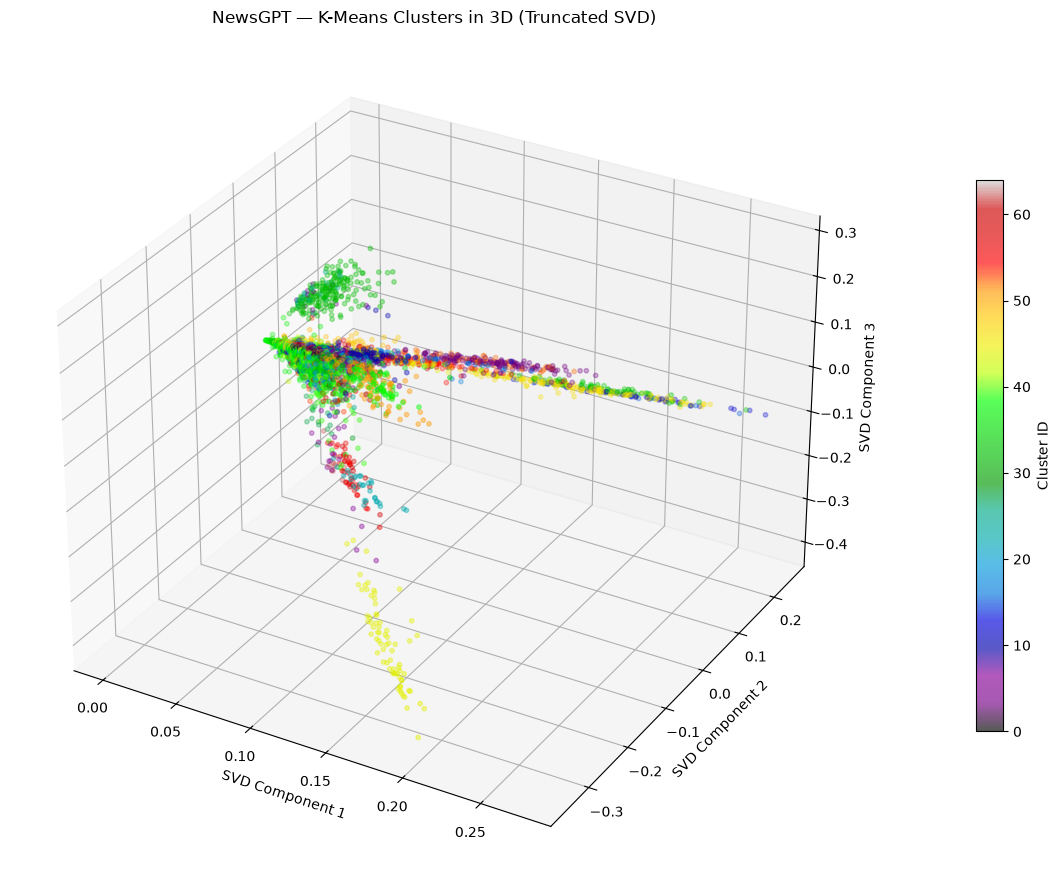

Articles visualized: 5,000
3D SVD explained variance: 1.04%
Note: SVD dimensions are projections of TF-IDF features, not literal topic coordinates.


In [54]:
# Cell 53 — Visualize K-Means clusters in 3D using Truncated SVD

import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD

# Use a reproducible sample for visualization performance
viz_sample_size = min(5000, X_tfidf_improved.shape[0])
viz_rng = np.random.RandomState(42)
viz_indices = viz_rng.choice(
    X_tfidf_improved.shape[0],
    size=viz_sample_size,
    replace=False
)

X_viz_sample = X_tfidf_improved[viz_indices]
labels_viz = improved_kmeans_labels[viz_indices]

# Reduce sparse TF-IDF features to three dimensions
svd_3d = TruncatedSVD(n_components=3, random_state=42)
X_3d = svd_3d.fit_transform(X_viz_sample)

explained_variance = svd_3d.explained_variance_ratio_.sum()

# Plot interactive 3D scatter plot
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

scatter = ax.scatter(
    X_3d[:, 0],
    X_3d[:, 1],
    X_3d[:, 2],
    c=labels_viz,
    cmap="nipy_spectral",
    s=10,
    alpha=0.65
)

ax.set_title("NewsGPT — K-Means Clusters in 3D (Truncated SVD)")
ax.set_xlabel("SVD Component 1")
ax.set_ylabel("SVD Component 2")
ax.set_zlabel("SVD Component 3")

fig.colorbar(scatter, ax=ax, pad=0.1, shrink=0.65, label="Cluster ID")
plt.tight_layout()
plt.show()

print(f"Articles visualized: {viz_sample_size:,}")
print(f"3D SVD explained variance: {explained_variance:.2%}")
print("Note: SVD dimensions are projections of TF-IDF features, not literal topic coordinates.")

E:\Anaconda3\Lib\site-packages\xarray\core\dtypes.py:98: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  NAT_TYPES = {np.datetime64("NaT").dtype, np.timedelta64("NaT").dtype}


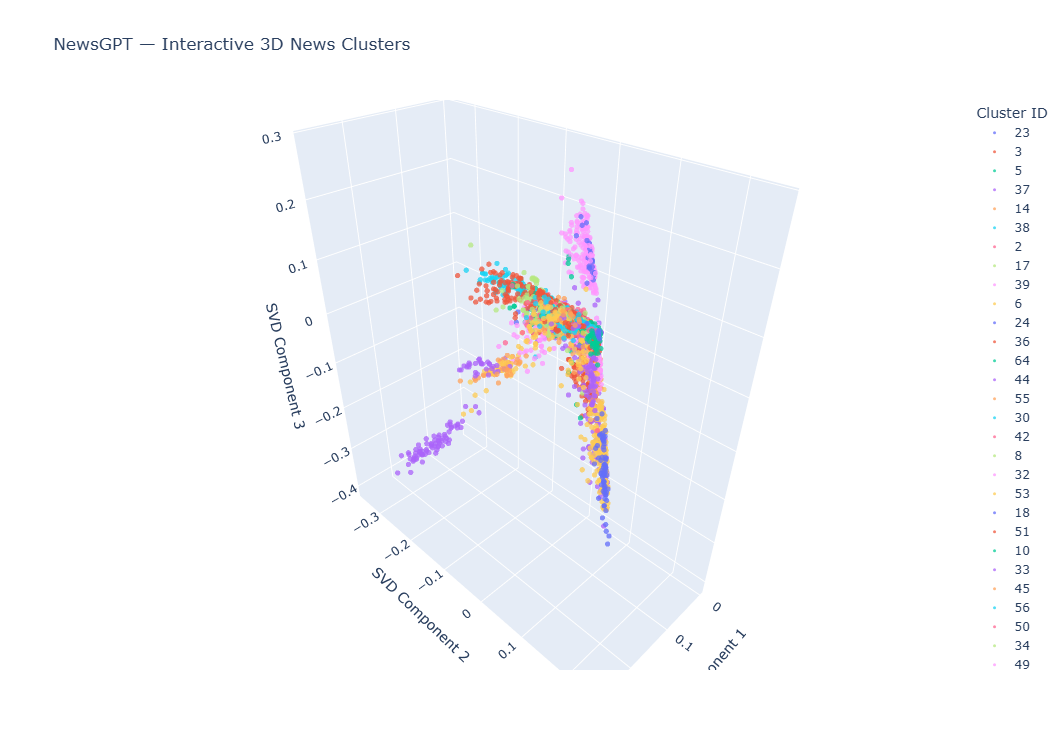

Articles visualized: 5,000
3D explained variance: 1.04%


In [55]:
# Cell 53 — Interactive 3D visualization of NewsGPT clusters

import plotly.express as px
from sklearn.decomposition import TruncatedSVD

# Sample articles for responsive visualization
viz_sample_size = min(5000, X_tfidf_improved.shape[0])

viz_rng = np.random.RandomState(42)
viz_indices = viz_rng.choice(
    X_tfidf_improved.shape[0],
    size=viz_sample_size,
    replace=False
)

X_viz_sample = X_tfidf_improved[viz_indices]
labels_viz = improved_kmeans_labels[viz_indices]

# Reduce TF-IDF vectors to 3 dimensions
svd_3d = TruncatedSVD(n_components=3, random_state=42)
X_3d = svd_3d.fit_transform(X_viz_sample)

# Prepare visualization data
viz_df = pd.DataFrame({
    "Component 1": X_3d[:, 0],
    "Component 2": X_3d[:, 1],
    "Component 3": X_3d[:, 2],
    "Cluster": labels_viz.astype(str),
    "Article ID": model_df.iloc[viz_indices]["article_id"].astype(str).to_numpy(),
    "Title": (
        model_df.iloc[viz_indices]["title"]
        .fillna("Untitled")
        .to_numpy()
    )
})

# Interactive 3D scatter plot
fig = px.scatter_3d(
    viz_df,
    x="Component 1",
    y="Component 2",
    z="Component 3",
    color="Cluster",
    hover_name="Title",
    hover_data=["Article ID"],
    opacity=0.75,
    title="NewsGPT — Interactive 3D News Clusters",
    height=750
)

fig.update_traces(marker=dict(size=3))
fig.update_layout(
    scene=dict(
        xaxis_title="SVD Component 1",
        yaxis_title="SVD Component 2",
        zaxis_title="SVD Component 3",
        aspectmode="data"
    ),
    legend_title_text="Cluster ID"
)

fig.show()

print(f"Articles visualized: {viz_sample_size:,}")
print(
    "3D explained variance: "
    f"{svd_3d.explained_variance_ratio_.sum():.2%}"
)

In [56]:
# Cell 54 — Inspect the largest clusters in the improved model

improved_cluster_sizes = (
    pd.Series(improved_kmeans_labels)
    .value_counts()
    .sort_values(ascending=False)
)

print("TOP 10 LARGEST CLUSTERS\n")

for cluster_id, size in improved_cluster_sizes.head(10).items():
    cluster_mask = improved_kmeans_labels == cluster_id
    cluster_indices = np.flatnonzero(cluster_mask)

    centroid = improved_kmeans_model.cluster_centers_[cluster_id]
    top_indices = np.argsort(centroid)[-12:][::-1]
    top_terms = improved_vectorizer.get_feature_names_out()[top_indices]

    print(f"Cluster {cluster_id} | Articles: {size:,}")
    print("Top terms:", ", ".join(top_terms))

    sample_indices = cluster_indices[:5]
    for idx in sample_indices:
        title = model_df.iloc[idx]["title"]
        print(f"  - {title if pd.notna(title) else 'Untitled'}")

    print("-" * 80)

TOP 10 LARGEST CLUSTERS

Cluster 37 | Articles: 3,714
Top terms: 2023, government, said, climate, health, 2024, amazon, minister, global, state, world, 10
  - A Twist For Adam Neumann, Sam Altman, And The Fate Of Female Founders
  - CyberPowerPC - Gamer Supreme Gaming Desktop - AMD Ryzen 9 7900X - 32GB Memory - NVIDIA GeForce RTX 4080 16GB - 2TB SSD - Black $2139.99
  - 中国连续6个月减持美债 外汇储备不够用了？(图)
  - Employee Negativity Is Like Wildfire. Manage It Before It Spreads.
  - Why Is Cancer Focused MorphoSys Stock Trading Lower Today?
--------------------------------------------------------------------------------
Cluster 42 | Articles: 2,303
Top terms: just, like, years, time, love, best, home, people, post, world, life, year
  - Tenuta Villa Bellini - a meeting of history and viticultural excellence
  - 15 "Bad" Movies People Still Love
  - Percival's Polo's Are a Celeb Favorite—and Now They're 60% Off
  - Now Is Not the Time to Buy Tesla Stock
  - Language That Could Be Added to the Buy-and-

CLUSTER DISTRIBUTION
Total articles: 22,357
Number of clusters: 65
Largest cluster: 3,714 articles (16.61%)
Smallest cluster: 29 articles
Mean cluster size: 344.0
Median cluster size: 199.0
Clusters with >500 articles: 7
Clusters with <50 articles: 5

CLUSTER SIZE PERCENTILES
count      65.000000
mean      343.953846
std       541.037326
min        29.000000
10%        56.400000
25%       106.000000
50%       199.000000
75%       382.000000
90%       635.200000
max      3714.000000
Name: count, dtype: float64


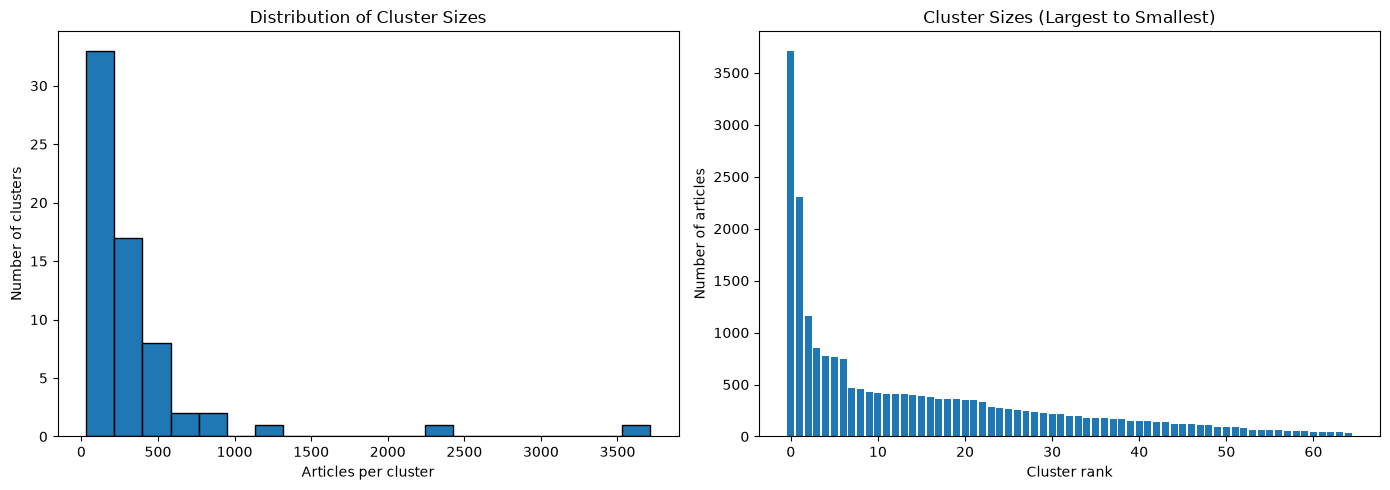

In [57]:
# Cell 55 — Cluster size distribution and coherence diagnostics

cluster_sizes = pd.Series(improved_kmeans_labels).value_counts()

print("CLUSTER DISTRIBUTION")
print(f"Total articles: {len(improved_kmeans_labels):,}")
print(f"Number of clusters: {len(cluster_sizes)}")
print(f"Largest cluster: {cluster_sizes.max():,} articles ({cluster_sizes.max() / len(improved_kmeans_labels):.2%})")
print(f"Smallest cluster: {cluster_sizes.min():,} articles")
print(f"Mean cluster size: {cluster_sizes.mean():.1f}")
print(f"Median cluster size: {cluster_sizes.median():.1f}")
print(f"Clusters with >500 articles: {(cluster_sizes > 500).sum()}")
print(f"Clusters with <50 articles: {(cluster_sizes < 50).sum()}")

print("\nCLUSTER SIZE PERCENTILES")
print(cluster_sizes.describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]))

# Visualize the distribution of cluster sizes
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(cluster_sizes, bins=20, edgecolor="black")
axes[0].set_title("Distribution of Cluster Sizes")
axes[0].set_xlabel("Articles per cluster")
axes[0].set_ylabel("Number of clusters")

axes[1].bar(
    np.arange(len(cluster_sizes)),
    cluster_sizes.sort_values(ascending=False).values
)
axes[1].set_title("Cluster Sizes (Largest to Smallest)")
axes[1].set_xlabel("Cluster rank")
axes[1].set_ylabel("Number of articles")

plt.tight_layout()
plt.show()

In [58]:
# Cell 56 — Analyze category distribution and potential language imbalance

print("CATEGORY DISTRIBUTION")
print(f"Unique categories: {model_df['category'].nunique()}")
print("\nTop 20 categories:")
print(model_df["category"].value_counts(dropna=False).head(20).to_string())

print("\nARTICLE LANGUAGE INDICATORS")
language_patterns = {
    "German": r"\b(der|die|das|und|ist|mit|von|fur|für)\b",
    "Spanish": r"\b(el|la|los|las|que|del|para|una)\b",
    "French": r"\b(le|les|des|une|est|pour|dans|avec)\b",
    "English": r"\b(the|and|is|for|with|that|this|from|said)\b",
    "Portuguese": r"\b(uma|para|com|não|dos|das|que|por)\b",
}

text_series = model_df["improved_text"].fillna("").str.lower()

for language, pattern in language_patterns.items():
    count = int(text_series.str.contains(pattern, regex=True).sum())
    print(f"{language}: {count:,} articles ({count / len(model_df):.1%})")

print("\nNote: These are rough keyword indicators, not reliable language detection.")

CATEGORY DISTRIBUTION
Unique categories: 114

Top 20 categories:
category
Argentina                  814
Home                       722
Love                       678
Games                      656
Art                        606
Food                       600
Stock                      597
China                      532
Australia                  530
Artificial Intelligence    523
Design                     499
Climate                    498
Space                      493
Amazon                     492
COVID                      472
Canada                     466
Politics                   454
France                     444
Health                     420
History                    415

ARTICLE LANGUAGE INDICATORS


C:\Users\swarup katkar\AppData\Local\Temp\ipykernel_24800\2046012966.py:20: UserWarning:

This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.



German: 1,425 articles (6.4%)
Spanish: 3,658 articles (16.4%)
French: 1,629 articles (7.3%)
English: 16,221 articles (72.6%)
Portuguese: 4,015 articles (18.0%)

Note: These are rough keyword indicators, not reliable language detection.


In [59]:
# Cell 57 — Refine language indicators and inspect text quality

language_patterns = {
    "German": r"\b(?:der|die|das|und|ist|mit|von|für)\b",
    "Spanish": r"\b(?:el|la|los|las|que|del|para|una)\b",
    "French": r"\b(?:le|les|des|une|est|pour|dans|avec)\b",
    "English": r"\b(?:the|and|is|for|with|that|this|from|said)\b",
    "Portuguese": r"\b(?:uma|para|com|não|dos|das|que|por)\b",
}

text_series = model_df["improved_text"].fillna("").str.lower()

language_counts = {}
for language, pattern in language_patterns.items():
    mask = text_series.str.contains(pattern, regex=True, na=False)
    language_counts[language] = int(mask.sum())

language_report = pd.DataFrame({
    "Language indicator": language_counts.keys(),
    "Articles matched": language_counts.values(),
    "Percentage of dataset": [
        count / len(model_df) * 100
        for count in language_counts.values()
    ]
}).sort_values("Articles matched", ascending=False)

print("LANGUAGE KEYWORD INDICATORS — OVERLAPPING ESTIMATES")
print(language_report.to_string(
    index=False,
    formatters={"Percentage of dataset": "{:.2f}%".format}
))

print("\nTEXT QUALITY SUMMARY")
print(f"Empty texts: {int(text_series.str.strip().eq('').sum()):,}")
print(f"Texts under 20 characters: {int(model_df['improved_text'].str.len().lt(20).sum()):,}")
print(f"Texts under 10 words: {int(model_df['improved_text'].str.split().str.len().lt(10).sum()):,}")
print(f"Duplicate article texts: {int(model_df['improved_text'].duplicated().sum()):,}")

print("\nSAMPLE ARTICLES WITH SHORT TEXT")
short_mask = model_df["improved_text"].str.split().str.len().lt(10)
print(
    model_df.loc[short_mask, ["article_id", "title", "improved_text"]]
    .head(10)
    .to_string(index=False, max_colwidth=100)
)

LANGUAGE KEYWORD INDICATORS — OVERLAPPING ESTIMATES
Language indicator  Articles matched Percentage of dataset
           English             16221                72.55%
        Portuguese              4015                17.96%
           Spanish              3658                16.36%
            French              1629                 7.29%
            German              1423                 6.36%

TEXT QUALITY SUMMARY
Empty texts: 0
Texts under 20 characters: 0
Texts under 10 words: 22
Duplicate article texts: 258

SAMPLE ARTICLES WITH SHORT TEXT
 article_id                                                  title                                                                                        improved_text
     594862          BAD HOPが3000人規模の入場無料イベントを今週末に開催、豪華アーティストが出演予定 BAD HOPが3000人規模の入場無料イベントを今週末に開催、豪華アーティストが出演予定 BAD HOPが地元である神奈川県川崎市のちどり公園で入場無料のライブイベント「Home Steal」...
     598751                           韓国人「来年から変わるペプシコーラのロゴをご覧ください」          韓国人「来年から変わるペプシコーラのロゴをご覧ください」 

In [60]:
# Cell 58 — Investigate duplicate article texts without deleting anything

duplicate_mask = model_df["improved_text"].duplicated(keep=False)

duplicate_articles = model_df.loc[
    duplicate_mask,
    ["article_id", "title", "category", "improved_text"]
].sort_values("improved_text")

print(f"Articles belonging to duplicate-text groups: {len(duplicate_articles):,}")
print(f"Duplicate occurrences beyond first copies: {int(model_df['improved_text'].duplicated().sum()):,}")
print(f"Unique duplicated text groups: {duplicate_articles['improved_text'].nunique():,}")

print("\nSAMPLE DUPLICATE GROUPS\n")

shown = 0
for text, group in duplicate_articles.groupby("improved_text", sort=False):
    if len(group) > 1:
        print(f"Copies: {len(group)}")
        print(group[["article_id", "title", "category"]].to_string(index=False))
        print(f"Text preview: {text[:250]}")
        print("-" * 80)
        shown += 1

        if shown >= 10:
            break

Articles belonging to duplicate-text groups: 491
Duplicate occurrences beyond first copies: 258
Unique duplicated text groups: 233

SAMPLE DUPLICATE GROUPS

Copies: 2
 article_id                                                                                 title category
     627225 2 декабря Fortnite ждет событие The Big Bang, которое знаменует новое начало для игры    Games
     627232 2 декабря Fortnite ждет событие The Big Bang, которое знаменует новое начало для игры    Games
Text preview: 2 декабря Fortnite ждет событие The Big Bang, которое знаменует новое начало для игры Осталось дождаться события и наблюдать за тем, что же такого грандиозного подготовили игрокам. Fortnite The Big Bang, LEGO . The Big Bang 2 21:00 (EET). Epic Games 
--------------------------------------------------------------------------------
Copies: 2
 article_id                                                                                          title category
     608661 56% of enterprises globally 

In [61]:
# Cell 59 — Finalize and save the selected K-Means model

import json
import joblib
from datetime import datetime

FINAL_OUTPUT_DIR = OUTPUT_DIR / "final_kmeans_k65"

# Protect existing files from accidental overwriting
if FINAL_OUTPUT_DIR.exists():
    raise FileExistsError(
        f"Output directory already exists: {FINAL_OUTPUT_DIR}\n"
        "Existing artifacts were not overwritten. Choose a new directory name if needed."
    )

FINAL_OUTPUT_DIR.mkdir(parents=True)

# 1. Save trained model and TF-IDF vectorizer
joblib.dump(
    improved_kmeans_model,
    FINAL_OUTPUT_DIR / "kmeans_k65_model.joblib"
)

joblib.dump(
    improved_vectorizer,
    FINAL_OUTPUT_DIR / "tfidf_vectorizer.joblib"
)

# 2. Save article-to-cluster assignments
final_assignments = model_df[
    ["article_id", "title", "category", "improved_text"]
].copy()

final_assignments["cluster_id"] = improved_kmeans_labels

final_assignments.drop(
    columns=["improved_text"]
).to_csv(
    FINAL_OUTPUT_DIR / "article_cluster_assignments.csv",
    index=False
)

# 3. Save the experiment metadata
metadata = {
    "project": "NewsGPT",
    "selected_algorithm": "K-Means",
    "text_representation": "TF-IDF",
    "number_of_clusters": 65,
    "max_features": 40000,
    "min_df": 3,
    "max_df": 0.85,
    "ngram_range": [1, 2],
    "stopwords": "English",
    "sublinear_tf": True,
    "random_state": 42,
    "dataset_articles": int(len(model_df)),
    "vocabulary_size": int(len(improved_vectorizer.vocabulary_)),
    "training_time_seconds": round(float(improved_training_time), 2)
        if "improved_training_time" in globals()
        else None,
    "inertia": float(improved_kmeans_model.inertia_),
    "silhouette_score": float(silhouette_improved)
        if "silhouette_improved" in globals()
        else (
            float(silhouette_improved_kmeans)
            if "silhouette_improved_kmeans" in globals()
            else 0.02794
        ),
    "silhouette_sample_size": 3000,
    "limitations": [
        "Some clusters contain semantically unrelated articles",
        "Multilingual stopword removal is incomplete",
        "Cluster sizes are uneven",
        "Silhouette score indicates substantial cluster overlap"
    ]
}

with open(
    FINAL_OUTPUT_DIR / "model_metadata.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(metadata, file, indent=4, ensure_ascii=False)

print("=" * 60)
print("FINAL MODEL SAVED SUCCESSFULLY")
print("=" * 60)
print(f"Model directory : {FINAL_OUTPUT_DIR}")
print(f"Articles        : {len(final_assignments):,}")
print(f"Clusters        : {improved_kmeans_model.n_clusters}")
print(f"Features        : {len(improved_vectorizer.vocabulary_):,}")
print(f"Inertia         : {improved_kmeans_model.inertia_:.4f}")
print("\nSaved artifacts:")
for path in sorted(FINAL_OUTPUT_DIR.iterdir()):
    print(f"  {path.name} ({path.stat().st_size / 1024:.1f} KB)")

FINAL MODEL SAVED SUCCESSFULLY
Model directory : D:\Projects\NewsGPT\outputs\final_kmeans_k65
Articles        : 22,357
Clusters        : 65
Features        : 40,000
Inertia         : 20868.0488

Saved artifacts:
  article_cluster_assignments.csv (2150.6 KB)
  kmeans_k65_model.joblib (10244.3 KB)
  model_metadata.json (0.8 KB)
  tfidf_vectorizer.joblib (1375.6 KB)


In [62]:
# Cell 60 — Verify final saved model artifacts

import joblib
import json

final_model_path = FINAL_OUTPUT_DIR / "kmeans_k65_model.joblib"
final_vectorizer_path = FINAL_OUTPUT_DIR / "tfidf_vectorizer.joblib"
final_assignments_path = FINAL_OUTPUT_DIR / "article_cluster_assignments.csv"
final_metadata_path = FINAL_OUTPUT_DIR / "model_metadata.json"

# Load saved artifacts
loaded_final_model = joblib.load(final_model_path)
loaded_final_vectorizer = joblib.load(final_vectorizer_path)
saved_assignments = pd.read_csv(final_assignments_path)

with open(final_metadata_path, "r", encoding="utf-8") as file:
    saved_metadata = json.load(file)

# Verify model configuration and saved assignments
assert loaded_final_model.n_clusters == 65
assert len(loaded_final_vectorizer.vocabulary_) == 40000
assert len(saved_assignments) == len(model_df)
assert saved_assignments["article_id"].is_unique
assert saved_assignments["cluster_id"].notna().all()

# Confirm assignments match the model output saved in the CSV
saved_cluster_ids = saved_assignments["cluster_id"].to_numpy()
original_cluster_ids = np.asarray(improved_kmeans_labels)

assignments_match = np.array_equal(
    saved_cluster_ids,
    original_cluster_ids
)

print("=" * 55)
print("FINAL ARTIFACT VERIFICATION")
print("=" * 55)
print(f"Model loaded successfully       : {loaded_final_model.n_clusters == 65}")
print(f"Vectorizer loaded successfully  : {len(loaded_final_vectorizer.vocabulary_) == 40000}")
print(f"Article count verified          : {len(saved_assignments):,}")
print(f"Unique article IDs              : {saved_assignments['article_id'].is_unique}")
print(f"All articles have assignments   : {saved_assignments['cluster_id'].notna().all()}")
print(f"Cluster assignments match       : {assignments_match}")
print(f"Metadata configuration          : {saved_metadata['selected_algorithm']} / K={saved_metadata['number_of_clusters']}")

assert assignments_match, "Saved cluster assignments differ from the current notebook assignments."

print("\nAll verification checks passed.")

E:\Anaconda3\Lib\site-packages\joblib\numpy_pickle.py:207: DeprecationWarning:

Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).



FINAL ARTIFACT VERIFICATION
Model loaded successfully       : True
Vectorizer loaded successfully  : True
Article count verified          : 22,357
Unique article IDs              : True
All articles have assignments   : True
Cluster assignments match       : True
Metadata configuration          : K-Means / K=65

All verification checks passed.


In [63]:
# Cell 61 — NewsGPT content-based recommendation function

from sklearn.metrics.pairwise import cosine_similarity

# Map each article's position to its existing cluster
recommendation_df = model_df[
    ["article_id", "title", "category", "improved_text"]
].copy()

recommendation_df["cluster_id"] = improved_kmeans_labels
recommendation_df = recommendation_df.reset_index(drop=True)


def recommend_articles(article_id, top_n=5):
    # Find the selected article
    matches = recommendation_df.index[
        recommendation_df["article_id"] == article_id
    ].tolist()

    if not matches:
        print(f"Article ID {article_id} was not found.")
        return pd.DataFrame()

    article_idx = matches[0]

    # Compare the selected article against all articles
    similarities = cosine_similarity(
        X_tfidf_improved[article_idx],
        X_tfidf_improved
    ).ravel()

    # Exclude the selected article itself
    similarities[article_idx] = -1

    # Select the most similar articles
    recommended_indices = np.argsort(similarities)[::-1][:top_n]

    results = recommendation_df.iloc[recommended_indices][
        ["article_id", "title", "category", "cluster_id"]
    ].copy()

    results["similarity_score"] = similarities[recommended_indices].round(4)

    selected_cluster = recommendation_df.loc[article_idx, "cluster_id"]
    results["same_cluster"] = results["cluster_id"] == selected_cluster

    print("SELECTED ARTICLE")
    print(f"Title: {recommendation_df.loc[article_idx, 'title']}")
    print(f"Category: {recommendation_df.loc[article_idx, 'category']}")
    print(f"Cluster: {selected_cluster}")

    print("\nRECOMMENDED ARTICLES")
    return results.reset_index(drop=True)


print("Recommendation function is ready.")

Recommendation function is ready.


In [64]:
# Cell 62 — Browse articles to select a test article

model_df[
    ["article_id", "title", "category"]
].sample(
    n=10,
    random_state=42
).reset_index(drop=True)

,article_id,title,category
0,596419,Govt is working on 5-6 rescue action plans at ...,Food
1,597097,"inZOI, une simulation de vie ultra-réaliste qu...",Games
2,625807,アルトマン氏、OpenAIのCEOに復帰。取締役会も刷新,Love
3,614137,Tata Motors commences sales of commercial vehi...,Thailand
4,595870,"Why Singapore is ‘friend of all, enemy of none...",Politics
5,604158,The Breast Pump Market is Expected to Reach US...,Brazil
6,620487,South African lawmakers vote to suspend diplom...,Jobs
7,621846,Broadcom planning to complete deal for $69 bil...,Technology
8,601465,UK Commercial Property shareholder blocks merger,Sustainability
9,625029,"First Watch Restaurant Group, Inc. (NASDAQ:FWR...",Stock


In [65]:
# Cell 63 — Generate recommendations for a selected article

test_article_id = 596419
recommendations = recommend_articles(
    article_id=test_article_id,
    top_n=5
)

recommendations

SELECTED ARTICLE
Title: Govt is working on 5-6 rescue action plans at Uttarakhand tunnel collapse site, says Road Secretary
Category: Food
Cluster: 23

RECOMMENDED ARTICLES


,article_id,title,category,cluster_id,similarity_score,same_cluster
0,596420,‘Govt is working on 5-6 rescue action plans at...,Food,23,0.9916,True
1,626796,Uttarkashi: Location for vertical drilling ide...,Food,23,0.3703,True
2,626606,"Tunnel collapse: Fresh fruits, medicines deliv...",Food,23,0.3169,True
3,608860,Uttarkashi tunnel collapse: First visuals of t...,India,23,0.3127,True
4,626705,Uttarkashi tunnel collapse updates: Back-up tu...,Food,23,0.3076,True


In [66]:
# Cell 64 — Inspect recommendation relevance and possible duplicates

selected_matches = recommendation_df.index[
    recommendation_df["article_id"] == test_article_id
].tolist()

if not selected_matches:
    print("Selected article was not found.")
else:
    selected_idx = selected_matches[0]
    selected_text = recommendation_df.loc[selected_idx, "improved_text"]

    print("SELECTED ARTICLE")
    print(f"ID: {test_article_id}")
    print(f"Title: {recommendation_df.loc[selected_idx, 'title']}")
    print(f"Text preview: {selected_text[:500]}")
    print("\n" + "=" * 80)

    for _, row in recommendations.iterrows():
        rec_idx = recommendation_df.index[
            recommendation_df["article_id"] == row["article_id"]
        ][0]

        rec_text = recommendation_df.loc[rec_idx, "improved_text"]

        print(f"\nArticle ID: {row['article_id']}")
        print(f"Title: {row['title']}")
        print(f"Category: {row['category']}")
        print(f"Similarity: {row['similarity_score']}")
        print(f"Same cluster: {row['same_cluster']}")
        print(f"Text preview: {rec_text[:350]}")
        print("-" * 80)

SELECTED ARTICLE
ID: 596419
Title: Govt is working on 5-6 rescue action plans at Uttarakhand tunnel collapse site, says Road Secretary
Text preview: Govt is working on 5-6 rescue action plans at Uttarakhand tunnel collapse site, says Road Secretary “The labourers are safe in the 2 km constructed section of the tunnel. There is electricity and water. Food and medicines are being delivered through the dedicated 4-inch compressor pipeline,” Road Secretary Anurag Jain said The Centre and State government are working on half a dozen action plans, including horizontal and vertical drilling to create a passage, to save labourers trapped inside the 


Article ID: 596420
Title: ‘Govt is working on 5-6 rescue action plans at Uttarakhand tunnel collapse site’
Category: Food
Similarity: 0.991599977016449
Same cluster: True
Text preview: ‘Govt is working on 5-6 rescue action plans at Uttarakhand tunnel collapse site’ “The labourers are safe in the 2 km constructed section of the tunnel. There is el

In [67]:
# Cell 65 — Recommend relevant articles while filtering near-duplicates

def recommend_articles(article_id, top_n=5, duplicate_threshold=0.95):
    matches = recommendation_df.index[
        recommendation_df["article_id"] == article_id
    ].tolist()

    if not matches:
        print(f"Article ID {article_id} was not found.")
        return pd.DataFrame()

    article_idx = matches[0]

    similarities = cosine_similarity(
        X_tfidf_improved[article_idx],
        X_tfidf_improved
    ).ravel()

    # Exclude the selected article itself
    similarities[article_idx] = -1

    # Exclude near-duplicates
    similarities[similarities >= duplicate_threshold] = -1

    # Select the highest remaining similarity scores
    recommended_indices = np.argsort(similarities)[::-1]
    recommended_indices = [
        idx for idx in recommended_indices
        if similarities[idx] >= 0
    ][:top_n]

    if not recommended_indices:
        print("No recommendations found after duplicate filtering.")
        return pd.DataFrame()

    results = recommendation_df.iloc[recommended_indices][
        ["article_id", "title", "category", "cluster_id"]
    ].copy()

    results["similarity_score"] = similarities[recommended_indices].round(4)
    results["same_cluster"] = (
        results["cluster_id"] == recommendation_df.loc[article_idx, "cluster_id"]
    )

    print("SELECTED ARTICLE")
    print(f"Title: {recommendation_df.loc[article_idx, 'title']}")
    print(f"Category: {recommendation_df.loc[article_idx, 'category']}")
    print(f"Cluster: {recommendation_df.loc[article_idx, 'cluster_id']}")

    print(f"\nRECOMMENDED ARTICLES (near-duplicates >= {duplicate_threshold} excluded)")
    return results.reset_index(drop=True)

In [68]:
# Cell 66 — Test recommendations after duplicate filtering

recommendations = recommend_articles(
    article_id=596419,
    top_n=5,
    duplicate_threshold=0.95
)

recommendations

SELECTED ARTICLE
Title: Govt is working on 5-6 rescue action plans at Uttarakhand tunnel collapse site, says Road Secretary
Category: Food
Cluster: 23

RECOMMENDED ARTICLES (near-duplicates >= 0.95 excluded)


,article_id,title,category,cluster_id,similarity_score,same_cluster
0,626796,Uttarkashi: Location for vertical drilling ide...,Food,23,0.3703,True
1,626606,"Tunnel collapse: Fresh fruits, medicines deliv...",Food,23,0.3169,True
2,608860,Uttarkashi tunnel collapse: First visuals of t...,India,23,0.3127,True
3,626705,Uttarkashi tunnel collapse updates: Back-up tu...,Food,23,0.3076,True
4,596571,"Uttarakhand Trapped Workers Get Veg Pulao, Mat...",Food,23,0.2843,True


In [69]:
# Cell 67 — Topic-based news recommendation engine

def recommend_by_topic(topic, top_n=10, duplicate_threshold=0.95):
    topic = str(topic).strip()

    if not topic:
        print("Please enter a topic, such as Technology or COVID-19.")
        return pd.DataFrame()

    # Transform the user's topic using the existing fitted vectorizer
    topic_vector = improved_vectorizer.transform([topic])

    if topic_vector.nnz == 0:
        print(
            f"No recognizable vocabulary found for '{topic}'. "
            "Try a more descriptive topic."
        )
        return pd.DataFrame()

    # Calculate similarity between the topic and every article
    similarities = cosine_similarity(
        topic_vector,
        X_tfidf_improved
    ).ravel()

    # Rank articles by similarity
    ranked_indices = np.argsort(similarities)[::-1]

    results = []
    selected_texts = []

    for idx in ranked_indices:
        score = float(similarities[idx])

        # Ignore articles with no matching vocabulary
        if score <= 0:
            break

        article_text = recommendation_df.iloc[idx]["improved_text"]

        # Remove duplicate and near-duplicate recommendations
        if any(
            cosine_similarity(
                improved_vectorizer.transform([article_text]),
                improved_vectorizer.transform([existing_text])
            )[0, 0] >= duplicate_threshold
            for existing_text in selected_texts
        ):
            continue

        results.append({
            "article_id": recommendation_df.iloc[idx]["article_id"],
            "title": recommendation_df.iloc[idx]["title"],
            "category": recommendation_df.iloc[idx]["category"],
            "cluster_id": recommendation_df.iloc[idx]["cluster_id"],
            "similarity_score": round(score, 4)
        })

        selected_texts.append(article_text)

        if len(results) >= top_n:
            break

    if not results:
        print(f"No relevant articles found for '{topic}'.")
        return pd.DataFrame()

    result_df = pd.DataFrame(results)

    print(f"Topic: {topic}")
    print(f"Recommendations found: {len(result_df)}")

    return result_df


print("Topic-based recommendation engine is ready.")

Topic-based recommendation engine is ready.


In [75]:
# Cell 68 — Test topic-based recommendations

topic_recommendations = recommend_by_topic(
    topic="COVID-19",
    top_n=10
)

topic_recommendations

Topic: COVID-19
Recommendations found: 10


,article_id,title,category,cluster_id,content_similarity,title_similarity,recommendation_score
0,619224,WHO：COVID-19变种病毒仍具威胁(图),COVID,0,0.5492,0.5774,0.5577
1,619383,Wołodymyr Zełenski o planie Rosji i zamachach ...,COVID,35,0.4589,0.7178,0.5366
2,603661,The new and improved COVID-19 vaccines will be...,Australia,0,0.4904,0.5556,0.5099
3,619648,В РАН предрекли рост заболеваемости COVID-19 п...,COVID,0,0.4498,0.6194,0.5007
4,619228,Эксперт назвала причину роста числа госпитализ...,COVID,0,0.3709,0.7706,0.4908
5,605943,Violations of Nuremberg Code in Covid-19 Contr...,Germany,0,0.4208,0.5998,0.4745
6,607791,States Where COVID-19 Is the Worst Right Now,Georgia,0,0.3546,0.7009,0.4585
7,619179,Eduscopio 2023: il Covid-19 rallenta carriera ...,COVID,54,0.2557,0.8715,0.4404
8,612162,Heavy-tailed distributions of confirmed COVID-...,New Zealand,0,0.4120,0.4846,0.4338
9,608496,ICMR denies link between COVID-19 vaccinations...,India,0,0.4323,0.4212,0.4290


In [74]:
# Cell 69 — Interactive NewsGPT topic recommendation interface

import ipywidgets as widgets
from IPython.display import display, clear_output

topic_input = widgets.Text(
    value="",
    placeholder="Try COVID-19, Technology, AI...",
    description="Topic:",
    layout=widgets.Layout(width="70%"),
    style={"description_width": "initial"}
)

recommend_button = widgets.Button(
    description="Find News",
    button_style="primary",
    icon="search"
)

result_output = widgets.Output()

def on_recommend_button_clicked(_):
    with result_output:
        clear_output(wait=True)

        results = recommend_by_topic(
            topic=topic_input.value,
            top_n=10
        )

        if not results.empty:
            display(results)

recommend_button.on_click(on_recommend_button_clicked)

display(
    widgets.VBox([
        widgets.HTML(
            "<h2>NewsGPT — Topic-Based News Recommendations</h2>"
            "<p>Enter a topic to discover related news articles.</p>"
        ),
        widgets.HBox([topic_input, recommend_button]),
        result_output
    ])
)

In [72]:
# Cell 71 — Improved topic-based recommendation ranking

def recommend_by_topic(topic, top_n=10, duplicate_threshold=0.95):
    topic = str(topic).strip()

    if not topic:
        print("Please enter a topic.")
        return pd.DataFrame()

    # Transform the topic using the existing fitted vectorizer
    topic_vector = improved_vectorizer.transform([topic])

    if topic_vector.nnz == 0:
        print(f"No recognizable vocabulary found for '{topic}'.")
        return pd.DataFrame()

    # Calculate content and title similarity separately
    content_scores = cosine_similarity(
        topic_vector, X_tfidf_improved
    ).ravel()

    title_texts = recommendation_df["title"].fillna("").astype(str)
    title_matrix = improved_vectorizer.transform(title_texts)

    title_scores = cosine_similarity(
        topic_vector, title_matrix
    ).ravel()

    # Combine the two scores
    combined_scores = (0.70 * content_scores) + (0.30 * title_scores)

    # Rank by combined relevance
    ranked_indices = np.argsort(combined_scores)[::-1]

    results = []
    selected_indices = []

    for idx in ranked_indices:
        score = float(combined_scores[idx])

        if score <= 0:
            break

        # Remove near-duplicate recommendations
        is_duplicate = False

        for selected_idx in selected_indices:
            pair_similarity = cosine_similarity(
                X_tfidf_improved[idx],
                X_tfidf_improved[selected_idx]
            )[0, 0]

            if pair_similarity >= duplicate_threshold:
                is_duplicate = True
                break

        if is_duplicate:
            continue

        row = recommendation_df.iloc[idx]

        results.append({
            "article_id": row["article_id"],
            "title": row["title"],
            "category": row["category"],
            "cluster_id": row["cluster_id"],
            "content_similarity": round(float(content_scores[idx]), 4),
            "title_similarity": round(float(title_scores[idx]), 4),
            "recommendation_score": round(score, 4)
        })

        selected_indices.append(idx)

        if len(results) >= top_n:
            break

    print(f"Topic: {topic}")
    print(f"Recommendations found: {len(results)}")

    return pd.DataFrame(results)


print("Updated recommendation function is ready.")

Updated recommendation function is ready.


In [73]:
# Cell 72 — Test COVID recommendations with title-aware ranking

topic_recommendations = recommend_by_topic(
    topic="covid",
    top_n=10
)

topic_recommendations

Topic: covid
Recommendations found: 10


,article_id,title,category,cluster_id,content_similarity,title_similarity,recommendation_score
0,619224,WHO：COVID-19变种病毒仍具威胁(图),COVID,0,0.4292,1.0000,0.6004
1,619612,"Covid, svolta in Piemonte: “Vaccini gratis per...",COVID,54,0.2850,0.3681,0.3099
2,619383,Wołodymyr Zełenski o planie Rosji i zamachach ...,COVID,35,0.2650,0.4144,0.3098
3,603511,Covid and flu vaccines: why take-up is so low ...,Australia,0,0.2621,0.3746,0.2958
4,603661,The new and improved COVID-19 vaccines will be...,Australia,0,0.2831,0.3208,0.2944
5,619179,Eduscopio 2023: il Covid-19 rallenta carriera ...,COVID,54,0.2030,0.5032,0.2931
6,605197,Maria Bartiromo Floats Wackadoodle COVID Theor...,China,8,0.2593,0.3700,0.2925
7,619648,В РАН предрекли рост заболеваемости COVID-19 п...,COVID,0,0.2597,0.3576,0.2891
8,615435,Why COVID Vaccines for Young Children Have Bee...,United States,37,0.2704,0.3292,0.2880
9,607783,COVID Map Shows 8 States With Rise in Deaths,Georgia,0,0.2696,0.3171,0.2838
